[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQC_GradientInversionPrivacy_Kumar2023.ipynb)

# Expressive variational quantum circuits and inherent privacy in federated learning: Kumar et al. (2023) step by step

**Paper reproduced.** N. Kumar, J. Heredge, C. Li, S. Eloul, S. H. Sureshbabu and M. Pistoia,
*Expressive variational quantum circuits provide inherent privacy in federated learning*, arXiv:2309.13002 (2023),
DOI [10.48550/arXiv.2309.13002](https://doi.org/10.48550/arxiv.2309.13002). (QC-292 in this repository.)

**What this notebook does.** In federated learning (FL) a client never uploads its data, only the *gradients* of the shared model. An
honest-but-curious server can still try to **invert** those gradients to recover the client's private input (a "gradient inversion attack").
The paper argues that if the shared model is a variational quantum circuit (VQC) with an *expressive* data encoding (the "Fourier tower":
`m` qubits per input, rotation angles `5^k * x`), the gradients are trigonometric polynomials of enormous degree `(5^m - 1)/2`, so matching them is a
high-degree polynomial system whose loss landscape has exponentially many local minima. This notebook rebuilds the circuit, checks it against a
real PennyLane circuit, runs the paper's numerical experiments (ADAM attack, local-minima counting, landscapes while the federated model trains),
and adds what the paper does not have: a **classical baseline on identical inputs**, a **stronger attacker**, and the same attack on **real data** (Iris).

**How to run.** Google Colab, CPU runtime, *Runtime > Run all*. With `FAST_MODE = True` (default in the config cell) it takes a few minutes;
`FAST_MODE = False` uses the paper's budgets (100 clients x 10 initialisations, landscapes up to m = 6 qubits, 10 repetitions). No dataset
download and no token is needed: the paper's inputs are synthetic by construction and the real-data extension uses Iris, which ships with scikit-learn.

**What you get at the end.** Re-drawn Figs. 4-13, a table of attack success against the number of qubits per input, the classical comparison, and a
claim-by-claim table (reproduced / not reached / cannot be checked).

## The paper in one page

* **Setting.** `l` clients each hold private data `(x, y)`; the server sends parameters `theta`, each client returns the `d` cost gradients
  `C_j = dCost/dtheta_j` computed on a mini-batch; the server averages and updates. Worst case for the client: **batch size 1**, noiseless exact gradients.
* **Why classical FL leaks (Sec. III C).** For a dense layer with softmax and cross-entropy, `dCost/dW_ij = (p_j - y_j) x_i` and `dCost/db_j = p_j - y_j`, so
  `x_i = (dCost/dW_ij) / (dCost/db_j)`: more equations than unknowns, the input is read off exactly.
* **Model.** VQC with the *Fourier tower* encoding `U(x) = (x)_{j=1..n} (x)_{k=1..m} RX(5^(k-1) gamma x_j)`, `gamma = 2 pi`, on `Nq = n m` qubits, followed by an
  over-parameterised hardware-efficient ansatz (blocks of `RY`-`RZ` on every qubit and a nearest-neighbour `CNOT` chain, `d = 2 L Nq >= 4 Nq`), output `<Z...Z>`,
  cost `(y - f)^2` with `y in {-1, +1}`, gradients by the parameter-shift rule.
* **Theory (not rerunnable).** The shared gradients form a system of multivariate Chebyshev/trigonometric polynomials of degree `(5^m - 1)/2` per input
  (`5^(mn)` frequencies); exact solving (Buchberger) and approximate solving (Nyquist-Shannon sampling) cost time and memory exponential in `Nq`; an ML attack
  is under-parameterised (only `n` unknowns) yet highly expressive, so its loss is riddled with spurious local minima.
* **Numerics (what we rerun).** (i) ADAM gradient-matching attack, `n = 1, m = 3`, `eta = 0.01`, 60 iterations, 100 random clients x 10 initialisations: the
  error `|x - x'|` is uniform (Fig. 4) and the success probability is linear in the tolerance, `R^2 = 0.993` (Fig. 5). (ii) Local minima of the single-gradient
  loss: `N_c = 0.622 exp(1.484 m)` (Fig. 6), valley spacing `r = 3.34 exp(-1.49 m)` (Fig. 10), distribution of minima (Fig. 9), 2-D landscapes (Fig. 8).
  (iii) Landscape of the attack while the FL model is trained on a target function (Figs. 11-13): a low-frequency fit with `m = 2` simplifies the landscape (less
  privacy), an `m = 4` model keeps the high frequencies and stays private.
* **Data.** None: client inputs are drawn uniformly in `[0, 1]^n`, labels in `{-1, +1}`, target functions `h` are synthetic. The paper names no dataset.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Encoding map | `RX(5^(k-1) gamma x_j)`, `gamma = 2 pi` | same; angle `u = gamma x in [0, 2 pi)` is the working variable |
| Observable, cost, labels | `Z...Z`, MSE, `y in {-1,1}` | same |
| Ansatz | HEA `RY-RZ` + nearest-neighbour `CNOT`, `d >= 4 Nq`; number of blocks not stated | `# CHOICE:` `L = 2` blocks for the attack experiments (`d = 4 Nq`, the smallest overparameterised value); `L = 4` for the models that have to be *trained* (Figs. 11-13, Iris): with `L = 2` the model cannot fit `0.7 cos x` (MSE stays 0.22 in our tests) although the paper's model fits it almost exactly; `RY` before `RZ`; open CNOT chain after the rotations |
| Simulator | Qiskit for the landscapes | `# CHOICE:` exact numpy state-vector simulator (needed for analytic input-derivatives), **asserted equal to a PennyLane QNode** (outputs, gradients, derivatives) |
| Gradients | parameter-shift, exact | same (shift `pi/2`) |
| Attack | ADAM `eta = 0.01`, 60 it, 100 clients x 10 inits, `n = 1, m = 3`, fixed random `theta` | same; loss summed over **all** `d` shared gradients; label `y` known to the server (worst case) |
| Error metric | closest angular distance on a circle (Eq. 99) | same (Euclidean norm of the circular errors for `n = 2`) |
| Landscape loss | one gradient `j`, random, not from the last layer (Eq. 100) | `# CHOICE:` `j` uniform over the parameters outside the last block; `j` redrawn when its gradient is identically zero ("dead" parameter, e.g. the first-block `RZ` on qubit 0 under the parity observable) |
| Counting minima | grid, "appropriate granularity" | `# CHOICE:` periodic grid with >= 16 points per period of the fastest frequency; strict local minima |
| Fig. 11-13 training | ADAM `eta = 0.01`, batch 10, 400 epochs; sample count not stated | `# CHOICE:` 50 training samples drawn uniformly in `[0, 2 pi]`; straight-line target `h = x/pi - 1` (a trigonometric polynomial cannot follow its jump at `x = 2 pi`); `L = 4`; `theta` random in `[0, 2 pi]`; attack landscape uses all `d` gradients |
| Repetitions | 100 x 10 (Fig. 4), 10 (Figs. 6, 9, 10) | same in the full run; fewer in `FAST_MODE` |
| Classical comparison | analytic dense-layer leak only | **added**: dense layer by autograd, classical MLP, MLP on Fourier features, same inputs and budgets |
| Stronger attacker | not studied | **added**: 5-10x larger optimiser budget |
| Real data | none | **added**: Iris (real flowers) through the same pipeline, `n = 2` |

## 0. Setup

PennyLane is the only extra library (the real circuit, `qml.draw_mpl`, autograd). It is pinned to the version tested here.

In [1]:
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
# Colab: pin the tested version. Locally nothing is reinstalled when PennyLane is already importable.
if IN_COLAB or not _have("pennylane"):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
    print("PennyLane installed. If the next cell fails to import it, use Runtime > Restart session and Run all again.")
else:
    print("PennyLane already available, nothing installed.")

PennyLane already available, nothing installed.


### Configuration

Every tunable constant lives in this cell. `FAST_MODE = True` is a quick class demo; set it to `False` for the full budgets.

In [2]:
import os
# Keep BLAS single-threaded: the simulations below are many small matrix products (set before numpy is imported).
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

SEED = 42
FAST_MODE = False          # True: small class demo (about 5 min); False: the full run (budgets below)
IBM_TOKEN = ""                # unused: the paper studies the ideal noiseless worst case, no hardware is needed
DATA_DIR = "qc292_cache"      # nothing is downloaded (Iris ships with scikit-learn); folder kept for convention
os.makedirs(DATA_DIR, exist_ok=True)

L_BLOCKS = 2                  # CHOICE: ansatz blocks L for the attack experiments A, B. d = 2*L*Nq = 4*Nq is the smallest value meeting Eq. 73 (d >= 4 Nq)
L_FL = 4                      # CHOICE: blocks for the models that must be TRAINED (Figs. 11-13, Iris). L = 2 cannot fit 0.7 cos x (MSE stays 0.22); L = 4 can
LR_PAPER, IT_PAPER = 0.01, 60 # paper: ADAM, eta = 0.01, 60 iterations (Fig. 4)
EPS_CLOSE = 0.1               # "successful attack": |x - x'| < 0.1 rad (Fig. 5 right uses 0 <= eps <= 0.1)

if FAST_MODE:
    CFG = dict(n_exp=30, n_att=10, m_sweep=[1, 2, 3, 4, 5], m_ext=[1, 2, 3], ext_iters=300, ext_lr=0.05,
               land_m=[1, 2, 3, 4, 5], land_reps=5, land2_m=[1, 2], land2_reps=3,
               fl_epochs=400, fl_ntrain=50, iris_epochs=25, iris_clients=12, iris_iters=300, iris_m=[1, 2, 3], brute_m=[1, 2, 3, 4], brute_clients=10)
else:
    CFG = dict(n_exp=100, n_att=10, m_sweep=[1, 2, 3, 4, 5, 6], m_ext=[1, 2, 3, 4], ext_iters=600, ext_lr=0.05,
               land_m=[1, 2, 3, 4, 5, 6], land_reps=10, land2_m=[1, 2, 3], land2_reps=4,
               fl_epochs=400, fl_ntrain=50, iris_epochs=40, iris_clients=20, iris_iters=400, iris_m=[1, 2, 3], brute_m=[1, 2, 3, 4, 5], brute_clients=20)
print("FAST_MODE =", FAST_MODE, "|", CFG)

FAST_MODE = False | {'n_exp': 100, 'n_att': 10, 'm_sweep': [1, 2, 3, 4, 5, 6], 'm_ext': [1, 2, 3, 4], 'ext_iters': 600, 'ext_lr': 0.05, 'land_m': [1, 2, 3, 4, 5, 6], 'land_reps': 10, 'land2_m': [1, 2, 3], 'land2_reps': 4, 'fl_epochs': 400, 'fl_ntrain': 50, 'iris_epochs': 40, 'iris_clients': 20, 'iris_iters': 400, 'iris_m': [1, 2, 3], 'brute_m': [1, 2, 3, 4, 5], 'brute_clients': 20}


In [3]:
import time, zlib, warnings, functools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import autograd, autograd.numpy as anp
import scipy, sklearn
from scipy import stats
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
TWO_PI = 2 * np.pi

def rng_for(name):
    """Independent, reproducible random stream per experiment (does not depend on FAST_MODE or on run order)."""
    return np.random.default_rng([SEED, zlib.crc32(name.encode())])

np.random.seed(SEED)
print("pennylane", qml.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

pennylane 0.45.1 | numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | matplotlib 3.11.2


### The exact simulator

The VQC has at most `Nq = 6` qubits here, so the state vector has at most 64 amplitudes. We simulate it exactly with NumPy because the *attack* needs the derivative
of the shared gradients with respect to the guess `x'` (a second-order quantity). The encoding is a product state, so `d psi / du_i = -i/2 sum_k 5^k X_(i,k) psi` is exact, and every
shared gradient is `C_p = -(y - f)(f(theta_p + pi/2) - f(theta_p - pi/2))` (Eq. 28), where each `f = <psi| W^dagger Z..Z W |psi>`. Section 2 asserts that this
simulator equals a real PennyLane QNode to machine precision, so no result below depends on trusting it blindly.

In [4]:
def circ_dist(a, b):
    """Closest angular distance on a circle (paper Eq. 99), elementwise."""
    d = np.abs(np.asarray(a) - np.asarray(b)) % TWO_PI
    return np.minimum(d, TWO_PI - d)


class FourierTowerVQC:
    """Exact simulator of the paper's variational circuit (state vector, no sampling noise).
    encoding : Fourier tower, qubit (i, k) gets RX(5**k * u_i), with u_i = gamma*x_i in [0, 2*pi), k = 0..m-1 (Eq. 61)
    ansatz   : L blocks; each block = RY then RZ on every qubit, then an open CNOT chain (0,1),(1,2),... (Eq. 17)
    output   : f(u, theta) = <Z x ... x Z>, cost = (y - f)^2, gradient by the parameter-shift rule (Eqs. 27-28)
    Qubit 0 is the most significant bit of the basis index (same convention as PennyLane)."""

    def __init__(self, n, m, L):
        self.n, self.m, self.L = n, m, L
        self.Nq = n * m
        self.D = 2 ** self.Nq
        self.d = 2 * L * self.Nq
        self.a = np.array([5.0 ** k for i in range(n) for k in range(m)])   # angle multiplier of each encoding gate
        self.owner = np.repeat(np.arange(n), m)                              # which input feeds each qubit
        idx = np.arange(self.D)
        bits = (idx[:, None] >> (self.Nq - 1 - np.arange(self.Nq))[None, :]) & 1
        self.zdiag = (1 - 2 * (bits.sum(1) % 2)).astype(float)               # eigenvalues of Z x ... x Z
        b = bits.copy()
        for j in range(self.Nq - 1):                                        # CNOT(0,1) then CNOT(1,2) ...
            b[:, j + 1] ^= b[:, j]
        out = (b * (1 << (self.Nq - 1 - np.arange(self.Nq)))[None, :]).sum(1)
        self.P = np.zeros((self.D, self.D)); self.P[out, idx] = 1.0

    @staticmethod
    def _ry(t):
        c, s = np.cos(t / 2), np.sin(t / 2)
        return np.array([[c, -s], [s, c]], dtype=complex)

    @staticmethod
    def _rz(t):
        return np.diag([np.exp(-0.5j * t), np.exp(0.5j * t)])

    def W_batch(self, thetas):
        """Ansatz unitaries W(theta) for a batch of parameter sets, thetas shape (K, L, Nq, 2) = (set, block, qubit, [RY, RZ])."""
        K = thetas.shape[0]
        U = np.broadcast_to(np.eye(self.D, dtype=complex), (K, self.D, self.D)).copy()
        for l in range(self.L):
            c, s = np.cos(thetas[:, l, :, 0] / 2), np.sin(thetas[:, l, :, 0] / 2)           # RY
            e = np.exp(-0.5j * thetas[:, l, :, 1])                                            # RZ = diag(e, conj(e))
            ry = np.zeros((K, self.Nq, 2, 2), dtype=complex)
            ry[..., 0, 0], ry[..., 0, 1], ry[..., 1, 0], ry[..., 1, 1] = c, -s, s, c
            g = np.empty_like(ry)                                                             # RZ @ RY, one 2x2 per qubit
            g[..., 0, :] = e[..., None] * ry[..., 0, :]
            g[..., 1, :] = np.conj(e)[..., None] * ry[..., 1, :]
            Kl = g[:, 0]
            for q in range(1, self.Nq):                                                       # Kronecker product over qubits
                Kl = np.einsum("kab,kcd->kacbd", Kl, g[:, q]).reshape(K, Kl.shape[1] * 2, Kl.shape[2] * 2)
            U = np.matmul(self.P, np.matmul(Kl, U))
        return U

    def W(self, theta):
        return self.W_batch(np.asarray(theta)[None])[0]

    def M(self, theta):
        W = self.W(theta)
        return W.conj().T @ (self.zdiag[:, None] * W)                        # Heisenberg-picture observable

    def shifted_theta(self, theta, p, s):
        t = np.asarray(theta).reshape(-1).copy(); t[p] += s * np.pi / 2
        return t.reshape(np.shape(theta))

    def Ms(self, theta, params=None):
        """[M(theta), M(theta_p +pi/2), M(theta_p -pi/2), ...] for the requested parameters (default all d)."""
        params = range(self.d) if params is None else params
        sets = [np.asarray(theta)]
        for p in params:
            for s in (+1, -1):
                sets.append(self.shifted_theta(theta, p, s))
        W = self.W_batch(np.array(sets))
        return np.matmul(W.conj().transpose(0, 2, 1), self.zdiag[None, :, None] * W)

    def psi(self, U):
        """Encoded product states for a batch of angle vectors U (B, n) -> (B, 2**Nq)."""
        U = np.atleast_2d(U); B = U.shape[0]
        ang = U[:, self.owner] * self.a[None, :]
        v = np.stack([np.cos(ang / 2), -1j * np.sin(ang / 2)], axis=-1)      # RX(ang)|0>
        psi = np.ones((B, 1), dtype=complex)
        for q in range(self.Nq):
            psi = (psi[:, :, None] * v[:, q, None, :]).reshape(B, -1)
        return psi

    def dpsi(self, psi):
        """Exact d psi / d u_i for every input i, shape (n, B, D): d RX(a u)/du = -i a/2 X RX."""
        B = psi.shape[0]
        out = np.zeros((self.n, B, self.D), dtype=complex)
        for q in range(self.Nq):
            xq = psi.reshape(B, 2 ** q, 2, -1)[:, :, ::-1, :].reshape(B, -1)
            out[self.owner[q]] += (-0.5j * self.a[q]) * xq
        return out

    def outputs(self, psi, Ms, dpsi=None):
        Mpsi = np.matmul(psi[None], Ms.transpose(0, 2, 1))                    # (K,B,D) = M|psi>
        f = np.real(np.einsum("bd,kbd->kb", psi.conj(), Mpsi))                # (K,B)
        if dpsi is None:
            return f, None
        df = 2 * np.real(np.einsum("kbd,ibd->kib", Mpsi.conj(), dpsi))        # (K,n,B)
        return f, df

    def cost_grads(self, psi, Ms, y, dpsi=None):
        """What a client shares: C_p = -(y - f)(f(theta_p+) - f(theta_p-)) for all p (Eq. 28), shape (d, B).
        With dpsi it also returns dC_p/du_i (n, d, B), needed by the server's gradient-matching attack."""
        f, df = self.outputs(psi, Ms, dpsi)
        f0, fp, fm = f[0], f[1::2], f[2::2]
        y = np.asarray(y, dtype=float)
        C = -(y - f0)[None, :] * (fp - fm)
        if df is None:
            return C, None
        df0, dfp, dfm = df[0], df[1::2], df[2::2]
        dC = df0[None, :, :] * (fp - fm)[:, None, :] - (y - f0)[None, None, :] * (dfp - dfm)
        return C, dC.transpose(1, 0, 2)

### The server's attack, landscapes and counting helpers

`vqc_attack` is the paper's attack: the server starts from a random guess `x'`, computes the gradients its own copy of the model would produce for `x'` and moves `x'` by ADAM to match the client's gradients. `landscape_points` evaluates the same loss on a dense grid so every critical point can be counted.

In [5]:
def adam_minimise(lossgrad, U0, lr, iters, wrap=False):
    """Plain ADAM (beta1 0.9, beta2 0.999) on a batch of independent attack problems.
    lossgrad(U) -> (loss (B,), grad (B, n)); U is (B, n). wrap=True keeps angles on [0, 2*pi)."""
    U = U0.copy(); m1 = np.zeros_like(U); m2 = np.zeros_like(U)
    b1, b2, eps = 0.9, 0.999, 1e-8
    for t in range(1, iters + 1):
        _, g = lossgrad(U)
        m1 = b1 * m1 + (1 - b1) * g
        m2 = b2 * m2 + (1 - b2) * g * g
        U = U - lr * (m1 / (1 - b1 ** t)) / (np.sqrt(m2 / (1 - b2 ** t)) + eps)
        if wrap:
            U = U % TWO_PI
    return U, lossgrad(U)[0]


def vqc_attack(model, Ms, y, C_target, U0, lr, iters):
    """Server-side gradient inversion on the VQC: minimise sum_p (C_p(u') - C_p*)^2 over the guess u'."""
    def lossgrad(U):
        psi = model.psi(U)
        C, dC = model.cost_grads(psi, Ms, y, model.dpsi(psi))
        r = C - C_target
        return (r ** 2).sum(0), 2 * np.einsum("pb,ipb->bi", r, dC)
    return adam_minimise(lossgrad, U0, lr, iters, wrap=True)


def attack_problems(model, theta, rng, n_exp, n_att):
    """n_exp clients, each with a private input u* and label y; the server tries n_att random initial guesses per client."""
    Ms = model.Ms(theta)
    ustar = rng.uniform(0, TWO_PI, (n_exp, model.n)); y = rng.choice([-1.0, 1.0], n_exp)
    us, ys = np.repeat(ustar, n_att, 0), np.repeat(y, n_att)
    Ct, _ = model.cost_grads(model.psi(us), Ms, ys)
    U0 = rng.uniform(0, TWO_PI, (n_exp * n_att, model.n))
    return Ms, us, ys, Ct, U0


def err_circ(U, ustar):
    return np.sqrt((circ_dist(U, ustar) ** 2).sum(1))          # Euclidean norm of the per-input circular errors


def success_curve(err, eps):
    return np.array([(err < e).mean() for e in eps])


def landscape_points(model, theta, y, u_star, Ugrid, params, full=False, chunk=16384):
    """Attack loss on a set of guesses. params=[j]: single-gradient loss L_j (Eq. 100); full=True: sum over all d gradients."""
    Ms = model.Ms(theta, params=None if full else params)
    Cs, _ = model.cost_grads(model.psi(np.atleast_2d(u_star)), Ms, np.array([y]))
    out = np.empty(len(Ugrid))
    for s in range(0, len(Ugrid), chunk):
        sl = slice(s, s + chunk)
        C, _ = model.cost_grads(model.psi(Ugrid[sl]), Ms, np.full(len(Ugrid[sl]), float(y)))
        out[sl] = ((C - Cs) ** 2).sum(0)
    return out


def grid_size_1d(m):
    return max(4096, 2 ** int(np.ceil(np.log2(16 * 5 ** m))))      # >= 16 points per period of the fastest frequency


def minima_1d(L):
    return np.where((L < np.roll(L, 1)) & (L <= np.roll(L, -1)))[0]

def maxima_1d(L):
    return np.where((L > np.roll(L, 1)) & (L >= np.roll(L, -1)))[0]

def minima_2d(L):
    """Strict local minima of a periodic 2-D array (smaller than all 8 neighbours)."""
    ok = np.ones(L.shape, bool)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di or dj:
                ok &= L < np.roll(np.roll(L, di, 0), dj, 1)
    return ok

### Classical comparison models

The classical reference is built from the same ingredients: a model, the cost `(y - f)^2`, the shared gradient vector, and the identical attack code (ADAM on `x'`, using automatic differentiation for the second-order term).

In [6]:
class ClassicalMLP:
    """Small classical network f(u) = v . tanh(W phi(u) + b) + c, cost (y-f)^2. Its shared gradient is the exact
    analogue of the VQC's C_p. phi = identity (plain MLP) or a Fourier-feature map [cos(5^k u), sin(5^k u)]."""

    def __init__(self, n_in, H, rng, m_feat=0):
        self.n_in, self.H, self.m_feat = n_in, H, m_feat
        self.d_in = n_in if m_feat == 0 else 2 * m_feat * n_in
        self.nparam = H * self.d_in + H + H + 1
        self.p = rng.normal(0, 1, self.nparam) / np.sqrt(np.r_[np.full(H * self.d_in, self.d_in), np.full(H, 1.0), np.full(H, H), 1.0])

    def phi(self, U):
        if self.m_feat == 0:
            return U
        return anp.concatenate([f(5.0 ** k * U) for k in range(self.m_feat) for f in (anp.cos, anp.sin)], axis=1)

    def unpack(self, p):
        H, d = self.H, self.d_in
        return p[:H * d].reshape(H, d), p[H * d:H * d + H], p[H * d + H:H * d + 2 * H], p[-1]

    def f(self, p, U):
        W, b, v, c = self.unpack(p)
        return anp.tanh(self.phi(U) @ W.T + b) @ v + c

    def grad_vec(self, p, U, y):
        """d(y-f)^2 / d(all weights), shape (B, nparam); differentiable in U (so the attack can be run by autograd)."""
        W, b, v, c = self.unpack(p)
        x = self.phi(U); t = anp.tanh(x @ W.T + b); fo = t @ v + c
        r = (-2 * (y - fo))[:, None]
        s = (1 - t ** 2) * v[None, :]
        gW = (r * s)[:, :, None] * x[:, None, :]
        return anp.concatenate([gW.reshape(U.shape[0], -1), r * s, r * t, r], axis=1)

    def closed_form_leak(self, ustar, y):
        """Analytic attack on the classical net: first-layer weight gradient / bias gradient = the network input phi(u) (batch size 1).
        For the plain MLP phi(u) = u; for the Fourier-feature MLP phi = [cos u, sin u, cos 5u, ...], so u = atan2(sin u, cos u)."""
        g = np.asarray(self.grad_vec(self.p, ustar, y)); B = g.shape[0]; H, d = self.H, self.d_in
        gW, gb = g[:, :H * d].reshape(B, H, d), g[:, H * d:H * d + H]
        h = np.argmax(np.abs(gb), axis=1); phi_hat = gW[np.arange(B), h] / gb[np.arange(B), h][:, None]
        if self.m_feat == 0:
            return phi_hat
        return (np.arctan2(phi_hat[:, 1], phi_hat[:, 0]) % TWO_PI)[:, None]

    def attack(self, U0, ustar, y, lr, iters):
        gstar = self.grad_vec(self.p, ustar, y)
        def loss_sum(U):
            return anp.sum((self.grad_vec(self.p, U, y) - gstar) ** 2)
        gfun = autograd.grad(loss_sum)
        def lossgrad(U):
            return ((self.grad_vec(self.p, U, y) - gstar) ** 2).sum(1), gfun(U)
        return adam_minimise(lossgrad, U0, lr, iters, wrap=False)


def dense_softmax_inversion(U, y01, rng):
    """Paper Sec. III C: a dense layer o = W u + b with softmax + cross-entropy leaks its input in closed form,
    u_i = (dCost/dW_ji) / (dCost/db_j) (Eq. 9). The gradients are computed by autograd, not by the formula."""
    n = U.shape[1]; errs = []
    for u, lab in zip(U, y01):
        W = anp.array(rng.normal(size=(2, n))); b = anp.array(rng.normal(size=2))
        def ce(Wb):
            Wm, bm = Wb[:2 * n].reshape(2, n), Wb[2 * n:]
            o = Wm @ u + bm; o = o - anp.max(o)
            return -(o[lab] - anp.log(anp.sum(anp.exp(o))))
        g = autograd.grad(ce)(anp.concatenate([W.reshape(-1), b]))
        gW, gb = g[:2 * n].reshape(2, n), g[2 * n:]
        j = int(np.argmax(np.abs(gb)))
        errs.append(np.abs(gW[j] / gb[j] - u).max())
    return np.array(errs)


class Adam:
    def __init__(self, size, lr):
        self.m1 = np.zeros(size); self.m2 = np.zeros(size); self.t = 0; self.lr = lr
    def step(self, p, g):
        self.t += 1
        self.m1 = 0.9 * self.m1 + 0.1 * g; self.m2 = 0.999 * self.m2 + 0.001 * g * g
        return p - self.lr * (self.m1 / (1 - 0.9 ** self.t)) / (np.sqrt(self.m2 / (1 - 0.999 ** self.t)) + 1e-8)

In [7]:
def train_vqc(model, theta0, U, y, epochs, bs, lr, rng, snapshots=()):
    """Federated-style local training: mini-batch ADAM on the batch-mean cost, gradients by parameter shift (Eq. 29)."""
    psi_all = model.psi(U)
    shape = theta0.shape; th = theta0.reshape(-1).copy(); opt = Adam(th.size, lr)
    snaps, mse = {}, []
    for ep in range(epochs + 1):
        Ms0 = model.Ms(th.reshape(shape), params=[])
        f = model.outputs(psi_all, Ms0)[0][0]
        mse.append(float(np.mean((y - f) ** 2)))
        if ep in snapshots:
            snaps[ep] = th.reshape(shape).copy()
        if ep == epochs:
            break
        perm = rng.permutation(len(U))
        for s in range(0, len(U), bs):
            idx = perm[s:s + bs]
            C, _ = model.cost_grads(psi_all[idx], model.Ms(th.reshape(shape)), y[idx])
            th = opt.step(th, C.mean(1))
    return th.reshape(shape), snaps, np.array(mse)


def train_mlp(mlp, U, y, epochs, bs, lr, rng):
    gfun = autograd.grad(lambda p, Ub, yb: anp.mean((yb - mlp.f(p, Ub)) ** 2))
    opt = Adam(mlp.nparam, lr)
    for ep in range(epochs):
        perm = rng.permutation(len(U))
        for s in range(0, len(U), bs):
            idx = perm[s:s + bs]
            mlp.p = opt.step(mlp.p, gfun(mlp.p, U[idx], y[idx]))

## 1. Dataset Exploration and Visualisation

**The paper has no dataset.** Its client inputs are drawn uniformly at random in `[0, 1]^n` and its labels from `{-1, +1}` (the recipe below is copied from the
paper, nothing is substituted). The federated model of Figs. 11-13 is trained on samples of a synthetic target function `h`. These recipe data are shown first.

Because attacking uniformly random numbers says little about real privacy, the notebook adds a **real dataset** for an extension experiment (Section 8): the Fisher
Iris measurements (150 real flowers, 4 features, 3 species, bundled with scikit-learn, no download). The model label is *setosa vs. the rest*.

synthetic client inputs: shape (1000,) | x range [0.000, 1.000] | label values {-1: 487, 1: 513}
federated training set for Figs. 11-13: shape (50,) | targets h_line in [-0.98, 0.94], h_cos in [-0.70, 0.70]


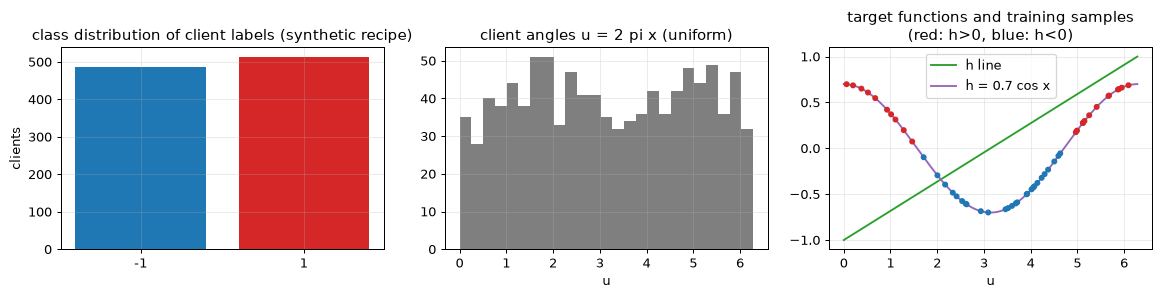

In [8]:
# The paper's own inputs: client data x ~ U[0,1]^n (gamma = 2*pi maps it to rotation angles u in [0, 2*pi)),
# client label y in {-1, +1}, and, for Figs. 11-13, a federated model that is trained on samples of a target function h.
rs = rng_for("data_synth")
x_clients = rs.uniform(0, 1, 1000); u_clients = 2 * np.pi * x_clients; y_clients = rs.choice([-1, 1], 1000)
H_LINE = lambda u: u / np.pi - 1.0          # CHOICE: "straight line" target of Fig. 11, spanning [-1, 1] on [0, 2*pi]
H_COS = lambda u: 0.7 * np.cos(u)           # Figs. 12-13: h(x) = 0.7 cos x
u_tr = rs.uniform(0, TWO_PI, CFG["fl_ntrain"])
print("synthetic client inputs: shape", x_clients.shape, "| x range [%.3f, %.3f]" % (x_clients.min(), x_clients.max()),
      "| label values", {int(k): int(v) for k, v in zip(*np.unique(y_clients, return_counts=True))})
print("federated training set for Figs. 11-13: shape", u_tr.shape, "| targets h_line in [%.2f, %.2f], h_cos in [%.2f, %.2f]"
      % (H_LINE(u_tr).min(), H_LINE(u_tr).max(), H_COS(u_tr).min(), H_COS(u_tr).max()))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
vals, cnt = np.unique(y_clients, return_counts=True)
ax[0].bar([str(v) for v in vals], cnt, color=["tab:blue", "tab:red"]); ax[0].set_title("class distribution of client labels (synthetic recipe)"); ax[0].set_ylabel("clients")
ax[1].hist(u_clients, bins=25, color="tab:gray"); ax[1].set_title("client angles u = 2 pi x (uniform)"); ax[1].set_xlabel("u")
uu = np.linspace(0, TWO_PI, 400)
ax[2].plot(uu, H_LINE(uu), "tab:green", label="h line"); ax[2].plot(uu, H_COS(uu), "tab:purple", label="h = 0.7 cos x")
ax[2].scatter(u_tr, H_COS(u_tr), c=np.where(H_COS(u_tr) > 0, "tab:red", "tab:blue"), s=14, zorder=3)
ax[2].set_title("target functions and training samples\n(red: h>0, blue: h<0)"); ax[2].set_xlabel("u"); ax[2].legend()
plt.tight_layout(); plt.show()

Iris (real measurements of 150 flowers): shape (150, 4)
feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
original label values: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')} | class counts: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}


train / test: 100 / 50


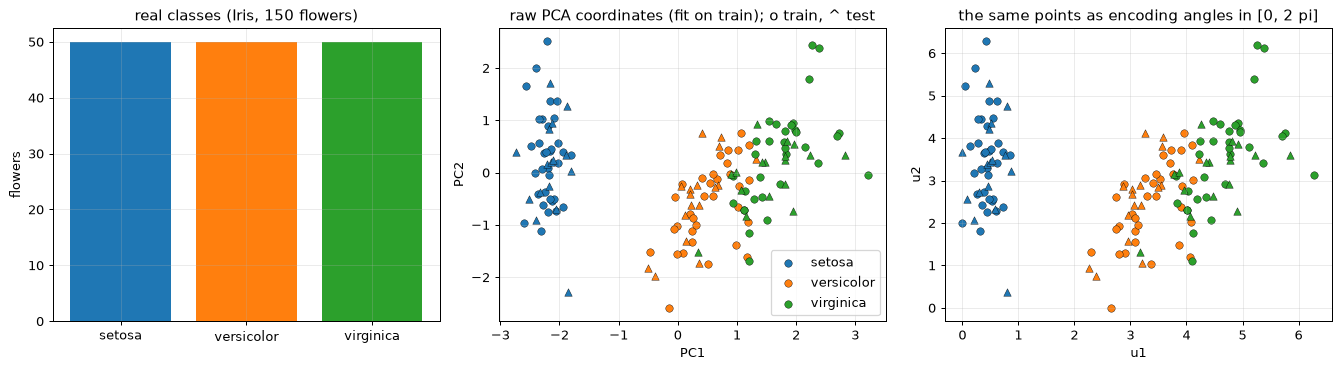

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
iris = load_iris(as_frame=True)
X_iris = iris.data.values; sp_iris = iris.target.values; FEATS = list(iris.feature_names); SPECIES = list(iris.target_names)
print("Iris (real measurements of 150 flowers): shape", X_iris.shape)
print("feature names:", FEATS)
print("original label values:", dict(enumerate(SPECIES)), "| class counts:", dict(zip(SPECIES, np.bincount(sp_iris))))
idx_tr, idx_te = train_test_split(np.arange(len(X_iris)), test_size=0.33, stratify=sp_iris, random_state=SEED)
print("train / test:", len(idx_tr), "/", len(idx_te))
# Pipeline of the extension (every transform fitted on the training split only): StandardScaler -> PCA(2) -> MinMax to [0, 2*pi]
std = StandardScaler().fit(X_iris[idx_tr]); pca = PCA(n_components=2, random_state=SEED).fit(std.transform(X_iris[idx_tr]))
Z_raw = pca.transform(std.transform(X_iris))
mm = MinMaxScaler((0, TWO_PI)).fit(Z_raw[idx_tr]); U_iris = np.clip(mm.transform(Z_raw), 0, TWO_PI)
y_iris = np.where(sp_iris == 0, 1.0, -1.0)           # CHOICE: model label +1 for setosa, -1 for versicolor/virginica
COL = ["tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].bar(SPECIES, np.bincount(sp_iris), color=COL); ax[0].set_title("real classes (Iris, 150 flowers)"); ax[0].set_ylabel("flowers")
for k, name in enumerate(SPECIES):
    for ids, mk in ((idx_tr, "o"), (idx_te, "^")):
        s = ids[sp_iris[ids] == k]
        ax[1].scatter(Z_raw[s, 0], Z_raw[s, 1], c=COL[k], marker=mk, edgecolor="k", linewidth=0.3, label=name if mk == "o" else None)
        ax[2].scatter(U_iris[s, 0], U_iris[s, 1], c=COL[k], marker=mk, edgecolor="k", linewidth=0.3)
ax[1].set_title("raw PCA coordinates (fit on train); o train, ^ test"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend()
ax[2].set_title("the same points as encoding angles in [0, 2 pi]"); ax[2].set_xlabel("u1"); ax[2].set_ylabel("u2")
plt.tight_layout(); plt.show()

## 2. Quantum Circuit Architecture

The circuit below is the one the experiments simulate: the Fourier-tower `RX` encoding (angles `5^k u`), `L = 2` (attack experiments) or `L = 4` (trained models) ansatz blocks of `RY`, `RZ` on every qubit followed by a
`CNOT` chain, and the parity measurement `Z...Z`. It is built as a real PennyLane QNode and drawn with `qml.draw_mpl`. One drawing per distinct architecture is shown (the
`m = 1..4` models of Figs. 4, 11-13 and the two-input `n = 2, m = 2` model of the Iris extension; larger `m` and the other Iris models only repeat the pattern with more qubits). Assumptions where the
paper is not explicit: `L = 2` (so `d = 4 Nq`, Eq. 73 with equality) or `L = 4` for trained models, `RY` applied before `RZ`, CNOT chain `0->1, 1->2, ...` after the rotations of each block, no final unitary.

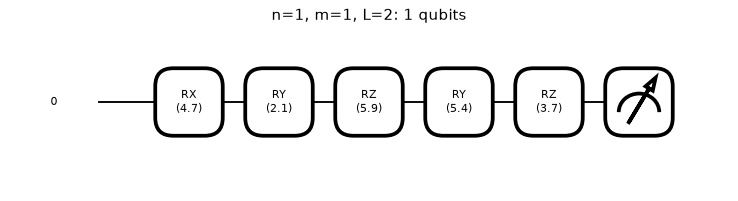

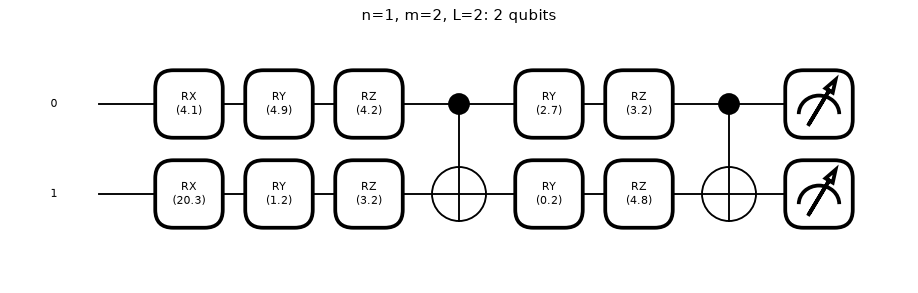

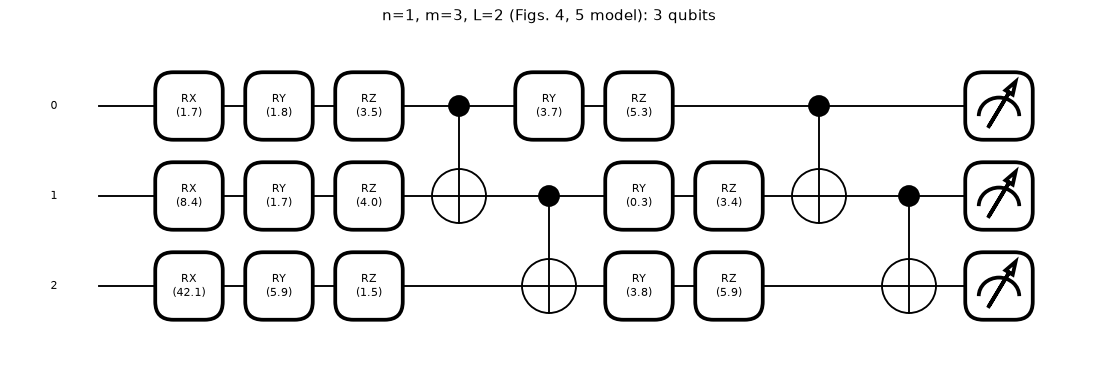

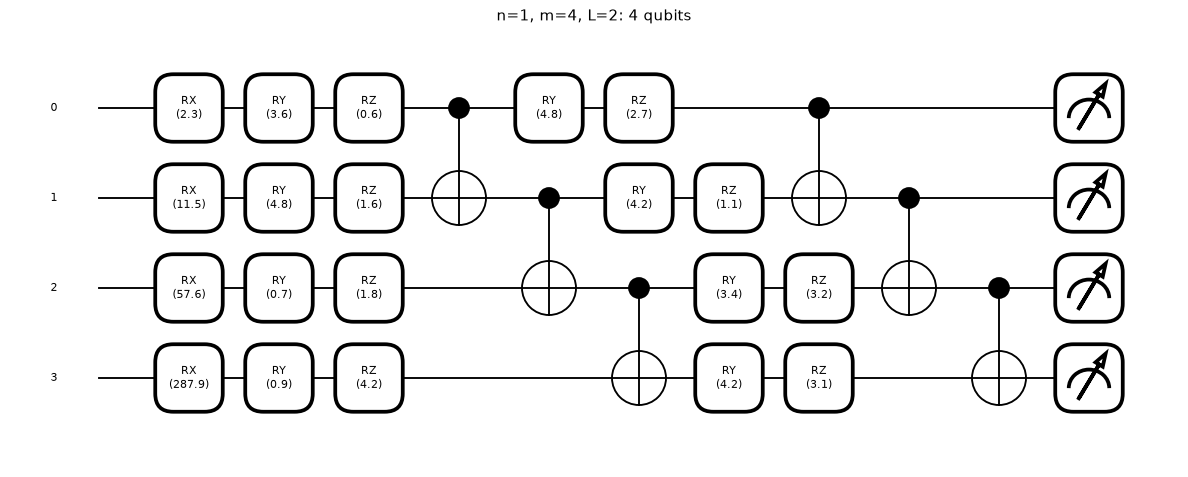

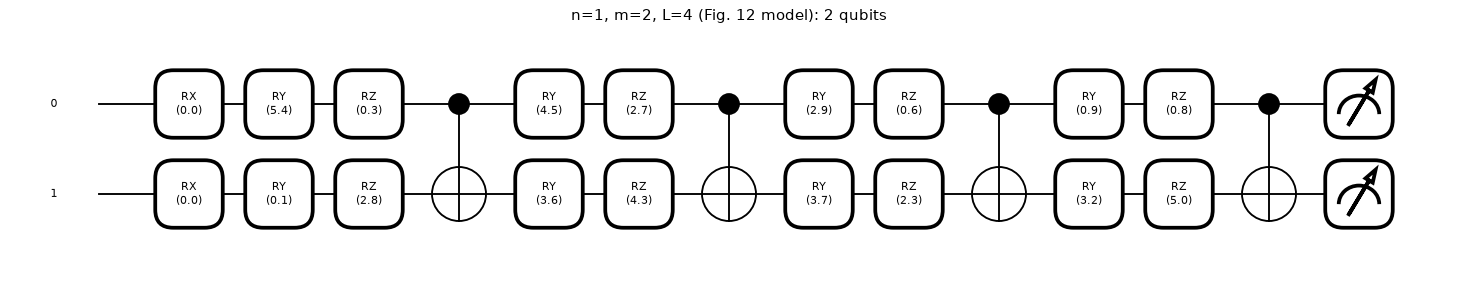

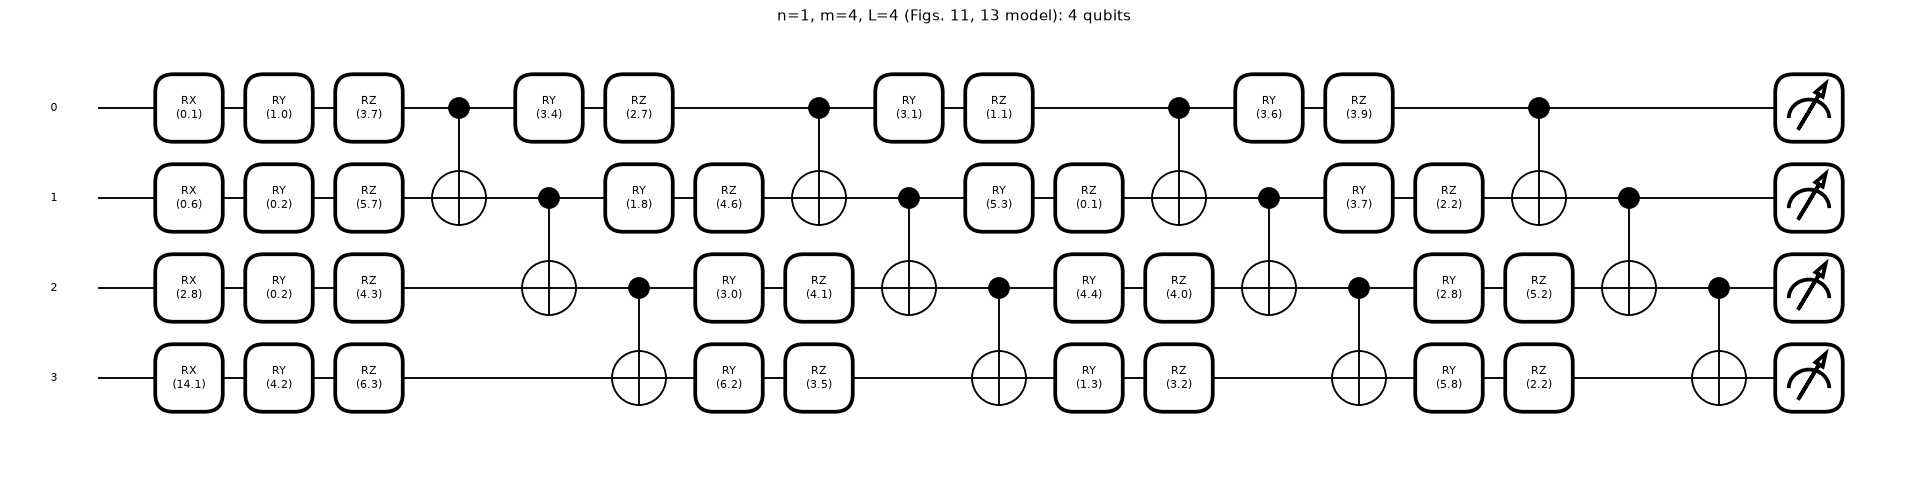

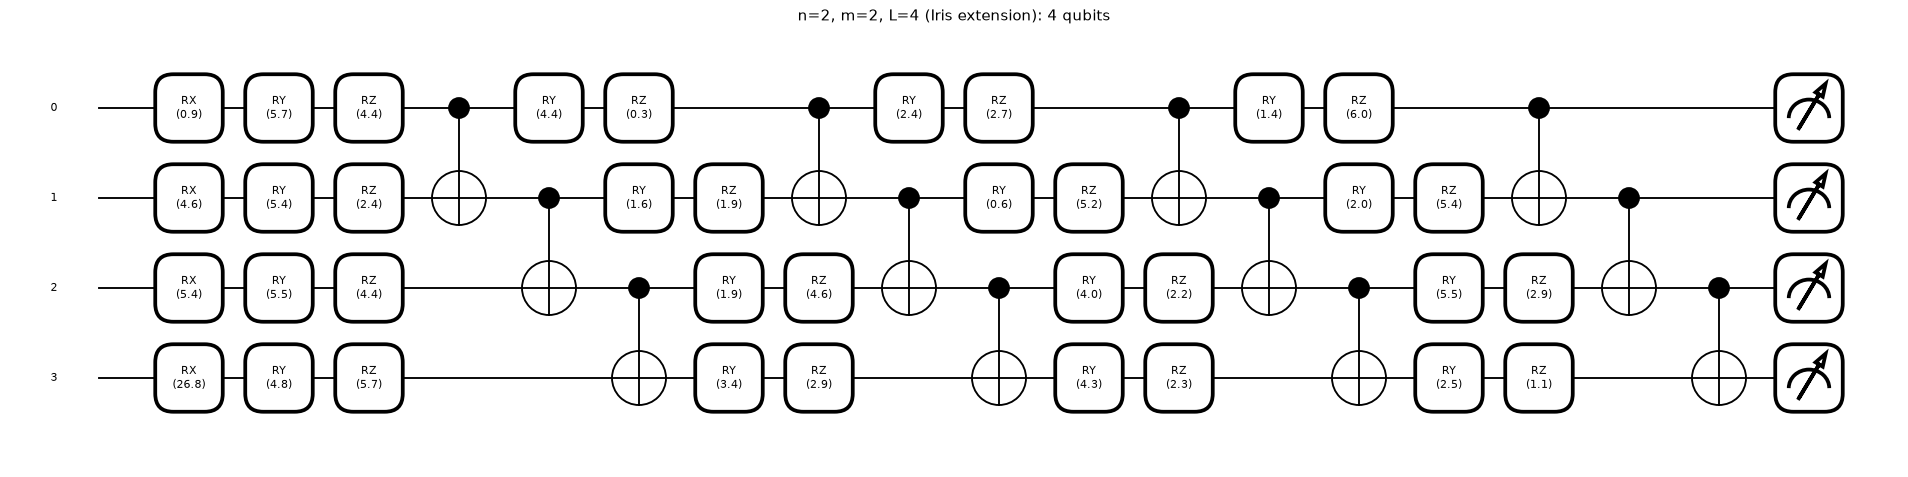

,architecture,qubits,depth,gates,trainable_params,overparam_cond_d_ge_4Nq,encoding_gates,gradient_degree_per_input
0,"n=1, m=1, L=2",1,5,5,4,True,1,2
1,"n=1, m=2, L=2",2,7,12,8,True,2,12
2,"n=1, m=3, L=2 (Figs. 4, 5 model)",3,9,19,12,True,3,62
3,"n=1, m=4, L=2",4,10,26,16,True,4,312
4,"n=1, m=2, L=4 (Fig. 12 model)",2,13,22,16,True,2,12
5,"n=1, m=4, L=4 (Figs. 11, 13 model)",4,18,48,32,True,4,312
6,"n=2, m=2, L=4 (Iris extension)",4,18,48,32,True,4,12


In [10]:
def make_qnode(model, diff_method="backprop"):
    """The real PennyLane circuit of the paper: Fourier-tower RX encoding, HEA blocks, <Z x ... x Z>."""
    dev = qml.device("default.qubit", wires=model.Nq)
    obs = functools.reduce(lambda a, b: a @ b, [qml.PauliZ(q) for q in range(1, model.Nq)], qml.PauliZ(0))
    @qml.qnode(dev, interface="autograd", diff_method=diff_method)
    def circuit(u, theta):
        for q in range(model.Nq):                                  # data encoding U(u): RX(5^k u_i) on qubit (i, k)
            qml.RX(model.a[q] * u[model.owner[q]], wires=q)
        for l in range(model.L):                                   # ansatz W(theta): L blocks
            for q in range(model.Nq):
                qml.RY(theta[l, q, 0], wires=q); qml.RZ(theta[l, q, 1], wires=q)
            for q in range(model.Nq - 1):
                qml.CNOT(wires=[q, q + 1])
        return qml.expval(obs)
    return circuit

ARCHS = [("n=1, m=1, L=2", 1, 1, L_BLOCKS), ("n=1, m=2, L=2", 1, 2, L_BLOCKS), ("n=1, m=3, L=2 (Figs. 4, 5 model)", 1, 3, L_BLOCKS),
         ("n=1, m=4, L=2", 1, 4, L_BLOCKS), ("n=1, m=2, L=4 (Fig. 12 model)", 1, 2, L_FL),
         ("n=1, m=4, L=4 (Figs. 11, 13 model)", 1, 4, L_FL), ("n=2, m=2, L=4 (Iris extension)", 2, 2, L_FL)]
rows = []
rc = rng_for("circuits")
for title, n, m, L_ in ARCHS:
    mod = FourierTowerVQC(n, m, L_); qn = make_qnode(mod)
    th = pnp.array(rc.uniform(0, TWO_PI, (L_, mod.Nq, 2)), requires_grad=True); u = pnp.array(rc.uniform(0, TWO_PI, n))
    fig, ax = qml.draw_mpl(qn, decimals=1, fontsize=9)(u, th)
    fig.suptitle(f"{title}: {mod.Nq} qubits", y=1.02); plt.show()
    spec = qml.specs(qn)(u, th)
    res = spec["resources"]
    rows.append(dict(architecture=title, qubits=mod.Nq, depth=res.depth, gates=res.num_gates, trainable_params=mod.d,
                     overparam_cond_d_ge_4Nq=bool(mod.d >= 4 * mod.Nq), encoding_gates=mod.Nq, gradient_degree_per_input=(5 ** m - 1) // 2))
display(pd.DataFrame(rows))

### The simulator equals the PennyLane circuit

For random angles and parameters (several architectures, plus one with `L = 3`) the output `f`, the parameter-shift cost gradients, `df/du` and `dC/du` of the NumPy simulator are compared with exact back-propagation through the PennyLane QNode. The cell raises an `AssertionError` unless they agree to `1e-8`.

In [11]:
# The numpy simulator used for all experiments is asserted equal to the PennyLane QNode above:
# output f, the parameter-shift cost gradients C_p (compared with exact back-propagation), df/du and dC/du.
re_ = rng_for("equivalence")
for title, n, m, L_ in ARCHS:
    mod = FourierTowerVQC(n, m, L_); qn = make_qnode(mod)
    th = re_.uniform(0, TWO_PI, (L_, mod.Nq, 2)); u = re_.uniform(0, TWO_PI, n); y = 1.0
    psi = mod.psi(u[None]); Ms = mod.Ms(th)
    C, dC = mod.cost_grads(psi, Ms, np.array([y]), mod.dpsi(psi)); f, df = mod.outputs(psi, Ms, mod.dpsi(psi))
    f_pl = float(qn(pnp.array(u), pnp.array(th)))
    g_pl = np.asarray(qml.grad(lambda t: (y - qn(pnp.array(u), t)) ** 2)(pnp.array(th, requires_grad=True))).reshape(-1)
    du_pl = np.asarray(qml.jacobian(lambda uu: qn(uu, pnp.array(th)))(pnp.array(u, requires_grad=True))).reshape(-1)
    dC_pl = np.asarray(qml.jacobian(lambda uu: qml.jacobian(lambda t: (y - qn(uu, t)) ** 2)(pnp.array(th, requires_grad=True)).reshape(-1))(pnp.array(u, requires_grad=True))).reshape(mod.d, n)
    e = [abs(f_pl - f[0, 0]), np.abs(g_pl - C[:, 0]).max(), np.abs(du_pl - df[0, :, 0]).max(), np.abs(dC_pl - dC[:, :, 0].T).max()]
    assert max(e) < 1e-8, (title, e)
    print(f"{title:32s} d={mod.d:3d}  max |simulator - PennyLane|: f {e[0]:.1e}  C {e[1]:.1e}  df/du {e[2]:.1e}  dC/du {e[3]:.1e}  -> equal")

n=1, m=1, L=2                    d=  4  max |simulator - PennyLane|: f 5.6e-17  C 2.2e-16  df/du 1.1e-16  dC/du 6.7e-16  -> equal


n=1, m=2, L=2                    d=  8  max |simulator - PennyLane|: f 1.9e-16  C 8.9e-16  df/du 0.0e+00  dC/du 2.1e-15  -> equal


n=1, m=3, L=2 (Figs. 4, 5 model) d= 12  max |simulator - PennyLane|: f 2.5e-16  C 6.1e-16  df/du 3.9e-15  dC/du 7.1e-15  -> equal


n=1, m=4, L=2                    d= 16  max |simulator - PennyLane|: f 3.5e-17  C 2.8e-16  df/du 5.3e-15  dC/du 3.3e-14  -> equal


n=1, m=2, L=4 (Fig. 12 model)    d= 16  max |simulator - PennyLane|: f 1.1e-16  C 1.5e-16  df/du 4.4e-16  dC/du 2.2e-15  -> equal


n=1, m=4, L=4 (Figs. 11, 13 model) d= 32  max |simulator - PennyLane|: f 1.4e-16  C 8.0e-16  df/du 5.3e-15  dC/du 5.7e-14  -> equal


n=2, m=2, L=4 (Iris extension)   d= 32  max |simulator - PennyLane|: f 2.8e-16  C 3.9e-16  df/du 4.4e-16  dC/du 2.8e-15  -> equal


## 3. Why the gradients are hard to invert: their Fourier spectrum

Eqs. 66-72: the Fourier-tower gradient can contain every integer frequency from `-(5^m - 1)/2` to `+(5^m - 1)/2`, i.e. `5^m` frequencies (degree `(5^m - 1)/2`). We test this by
sampling all shared gradient components on a grid and taking their FFT: is the top frequency really populated, and are all `5^m` frequencies populated? The model output itself has half that degree.

,m,gradient_degree_measured,paper_degree,frequencies_populated,paper_5_pow_m,fraction_populated,model_output_degree,model_output_degree_expected
0,1,2,2,5,5,1.00,1,1
1,2,12,12,21,25,0.84,6,6
2,3,62,62,91,125,0.73,31,31
3,4,312,312,339,625,0.54,156,156


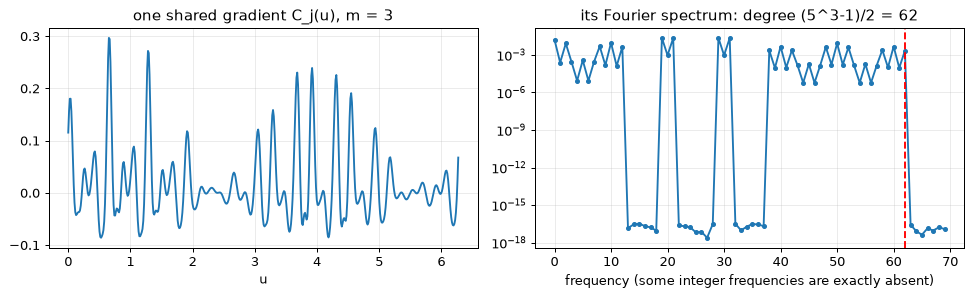

In [12]:
# Paper Sec. V B 1 (Eqs. 66-72): the cost gradient of the Fourier-tower VQC is a trigonometric polynomial in u whose
# frequencies are ALL integers in [-(5^m-1)/2, (5^m-1)/2]  (5^m of them, degree d_F = (5^m-1)/2).  We check this by FFT.
rsp = rng_for("spectrum")
rows = []
for m in [1, 2, 3, 4]:
    mod = FourierTowerVQC(1, m, L_BLOCKS)
    th = rsp.uniform(0, TWO_PI, (L_BLOCKS, mod.Nq, 2)); N = 8 * 5 ** m
    grid = np.arange(N) * TWO_PI / N
    Ms = mod.Ms(th)
    C, _ = mod.cost_grads(mod.psi(grid[:, None]), Ms, np.full(N, 1.0))
    fo = mod.outputs(mod.psi(grid[:, None]), Ms[:1])[0][0]
    c = np.abs(np.fft.fft(C, axis=1)) / N                  # spectrum of every shared gradient component
    freqs = np.abs(np.fft.fftfreq(N, d=1.0 / N)).astype(int)
    live = c > 1e-12 * c.max()                              # populated frequencies (relative threshold 1e-12)
    union = live.any(0)                                     # frequency present in at least one component
    fo_c = np.abs(np.fft.fft(fo)) / N
    rows.append(dict(m=m, gradient_degree_measured=int(freqs[union].max()), paper_degree=(5 ** m - 1) // 2,
                     frequencies_populated=int(union.sum()), paper_5_pow_m=5 ** m, fraction_populated=round(union.sum() / 5 ** m, 2),
                     model_output_degree=int(freqs[fo_c > 1e-12 * fo_c.max()].max()), model_output_degree_expected=(5 ** m - 1) // 4))
SPEC = pd.DataFrame(rows); display(SPEC)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
mod = FourierTowerVQC(1, 3, L_BLOCKS); th = rsp.uniform(0, TWO_PI, (L_BLOCKS, mod.Nq, 2)); N = 4 * 125
grid = np.arange(N) * TWO_PI / N; C, _ = mod.cost_grads(mod.psi(grid[:, None]), mod.Ms(th), np.full(N, 1.0))
ax[0].plot(grid, C[2]); ax[0].set_title("one shared gradient C_j(u), m = 3"); ax[0].set_xlabel("u")
cc = np.abs(np.fft.rfft(C[2])) / N; ax[1].semilogy(cc[:70] + 1e-18, ".-"); ax[1].set_title("its Fourier spectrum: degree (5^3-1)/2 = 62")
ax[1].axvline(62, color="r", ls="--"); ax[1].set_xlabel("frequency (some integer frequencies are exactly absent)")
plt.tight_layout(); plt.show()

## 4. The classical reference: a dense layer leaks its input

Section III C of the paper: with softmax + cross-entropy the input equals a ratio of two shared gradients. We compute the gradients with automatic differentiation (not with the formula) for 200 random clients and divide.

In [13]:
# Classical reference of Sec. III C: a dense softmax layer leaks its input in closed form from one gradient (batch size 1).
rcl = rng_for("dense")
u_test = rcl.uniform(0, TWO_PI, (200, 1)); lab = rcl.integers(0, 2, 200)
err_dense = dense_softmax_inversion(u_test, lab, rcl)
print("dense softmax layer, 200 clients, n=1: max recovery error %.2e, median %.2e   (exact recovery, as Eq. 9 says)" % (err_dense.max(), np.median(err_dense)))
u2 = rcl.uniform(0, TWO_PI, (200, 2)); err_dense2 = dense_softmax_inversion(u2, rcl.integers(0, 2, 200), rcl)
print("dense softmax layer, 200 clients, n=2: max recovery error %.2e" % err_dense2.max())

dense softmax layer, 200 clients, n=1: max recovery error 8.88e-16, median 0.00e+00   (exact recovery, as Eq. 9 says)


dense softmax layer, 200 clients, n=2: max recovery error 8.88e-16


## 5. Experiment A: the ADAM gradient-inversion attack (Figs. 4 and 5)

The server knows `theta` and the client's label `y`, receives the gradient vector, and minimises `sum_p (C_p(x') - C_p(x))^2` over its guess `x'`. Following Fig. 4, `theta` is a fixed random
vector, there are `n_exp` clients with random private `x`, and each is attacked from 10 random initial guesses. "Success" means a circular error below `eps`. A **random guess** succeeds with probability
`eps / pi`. We repeat this for several `m` (Fig. 5 right) and, beyond the paper, once more with a much larger optimiser budget, because ADAM with `eta = 0.01` for 60 iterations can only move `x'` by about 0.6 rad,
so part of the "failure" at the paper's budget could be a budget effect rather than a property of the landscape.

m=1: 1000 attacks done (4s)


m=2: 1000 attacks done (10s)


m=3: 1000 attacks done (50s)


m=4: 1000 attacks done (172s)


m=5: 1000 attacks done (194s)


m=6: 1000 attacks done (235s)


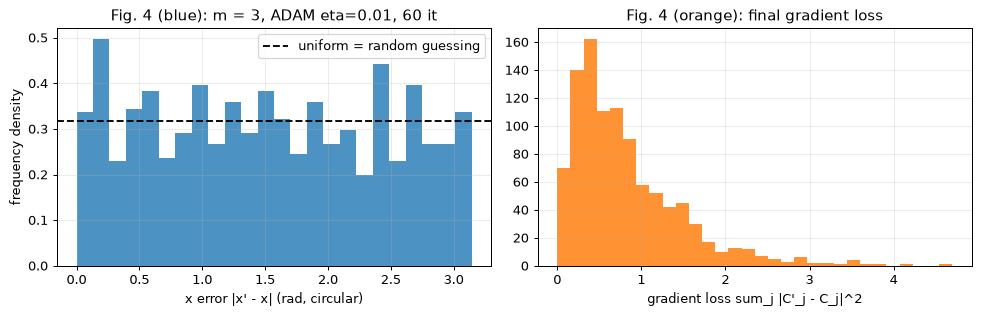

m=3: KS test of the error distribution against Uniform[0, pi]: statistic 0.036, p = 0.145 (p > 0.01: cannot reject 'uniform')


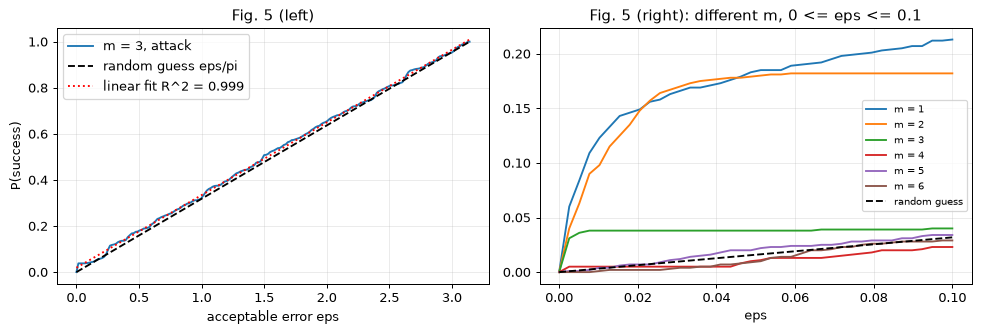

Linear fit of P(eps) for m=3: slope 0.315 (random guess: 0.318), R^2 = 0.9993  [paper: R^2 = 0.993]


In [14]:
# ---- Experiment A (Figs. 4 and 5): ADAM gradient-matching attack, n = 1, fixed random theta, many clients x many inits ----
ra = rng_for("expA")
EPS_GRID = np.linspace(0, np.pi, 200)
RES_A = {}
t0 = time.time()
for m in CFG["m_sweep"]:
    mod = FourierTowerVQC(1, m, L_BLOCKS)
    th = ra.uniform(0, TWO_PI, (L_BLOCKS, mod.Nq, 2))              # fixed randomly chosen theta (as in Fig. 4)
    Ms, us, ys, Ct, U0 = attack_problems(mod, th, ra, CFG["n_exp"], CFG["n_att"])
    U, loss = vqc_attack(mod, Ms, ys, Ct, U0, LR_PAPER, IT_PAPER)  # the paper's budget: eta = 0.01, 60 iterations
    RES_A[m] = dict(err=err_circ(U, us), loss=loss, err0=err_circ(U0, us))
    if m in CFG["m_ext"]:                                          # beyond the paper: a much stronger optimiser budget
        Ue, losse = vqc_attack(mod, Ms, ys, Ct, U0, CFG["ext_lr"], CFG["ext_iters"])
        RES_A[m].update(err_ext=err_circ(Ue, us), loss_ext=losse)
    print(f"m={m}: {len(U)} attacks done ({time.time()-t0:.0f}s)")

# Figure 4: error histogram + gradient loss, m = 3
r3 = RES_A[3]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(r3["err"], bins=np.linspace(0, np.pi, 25), density=True, color="tab:blue", alpha=0.8)
ax[0].axhline(1 / np.pi, color="k", ls="--", label="uniform = random guessing"); ax[0].set_xlabel("x error |x' - x| (rad, circular)"); ax[0].set_ylabel("frequency density")
ax[0].set_title("Fig. 4 (blue): m = 3, ADAM eta=0.01, 60 it"); ax[0].legend()
ax[1].hist(r3["loss"], bins=30, color="tab:orange", alpha=0.85); ax[1].set_xlabel("gradient loss sum_j |C'_j - C_j|^2"); ax[1].set_title("Fig. 4 (orange): final gradient loss")
plt.tight_layout(); plt.show()
ks = stats.kstest(r3["err"] / np.pi, "uniform")
print("m=3: KS test of the error distribution against Uniform[0, pi]: statistic %.3f, p = %.3f (p > 0.01: cannot reject 'uniform')" % (ks.statistic, ks.pvalue))

# Figure 5: success probability P(eps) = P(|x - x'| < eps)
P3 = success_curve(r3["err"], EPS_GRID)
slope, icpt, rval, _, _ = stats.linregress(EPS_GRID, P3); R2_LIN = rval ** 2
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(EPS_GRID, P3, label="m = 3, attack"); ax[0].plot(EPS_GRID, EPS_GRID / np.pi, "k--", label="random guess eps/pi")
ax[0].plot(EPS_GRID, icpt + slope * EPS_GRID, "r:", label=f"linear fit R^2 = {R2_LIN:.3f}")
ax[0].set_xlabel("acceptable error eps"); ax[0].set_ylabel("P(success)"); ax[0].set_title("Fig. 5 (left)"); ax[0].legend()
eps_s = np.linspace(0, 0.1, 40)
for m in CFG["m_sweep"]:
    ax[1].plot(eps_s, success_curve(RES_A[m]["err"], eps_s), label=f"m = {m}")
ax[1].plot(eps_s, eps_s / np.pi, "k--", label="random guess"); ax[1].set_xlabel("eps"); ax[1].set_title("Fig. 5 (right): different m, 0 <= eps <= 0.1"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Linear fit of P(eps) for m=3: slope %.3f (random guess: %.3f), R^2 = %.4f  [paper: R^2 = 0.993]" % (slope, 1 / np.pi, R2_LIN))

,m,qubits,params_d,chance_P_err_lt_0p1,init_guess_P,paper_budget_P,paper_budget_loss_below_1e6,strong_budget_P,strong_budget_loss_below_1e6
0,1,1,4,0.032,0.042,0.213,0.030,0.735,0.687
1,2,2,8,0.032,0.026,0.182,0.002,0.183,0.183
2,3,3,12,0.032,0.034,0.040,0.001,0.041,0.037
3,4,4,16,0.032,0.022,0.023,0.000,0.028,0.002
4,5,5,20,0.032,0.033,0.034,0.000,NaN,NaN
5,6,6,24,0.032,0.033,0.029,0.000,NaN,NaN


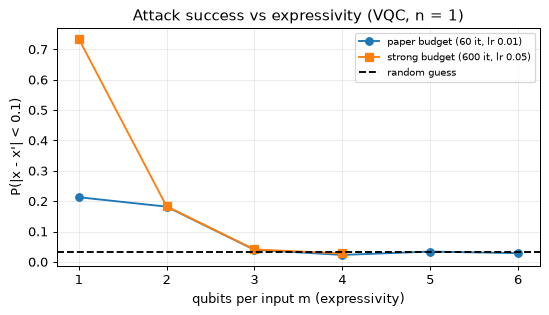

In [15]:
# Summary over expressivity m: paper budget vs a 10x stronger optimiser budget (beyond the paper), plus the "attack" of doing nothing (random initial guess).
rows = []
for m in CFG["m_sweep"]:
    r = RES_A[m]
    row = dict(m=m, qubits=m, params_d=2 * L_BLOCKS * m, chance_P_err_lt_0p1=round(0.1 / np.pi, 3),
               init_guess_P=round((r["err0"] < EPS_CLOSE).mean(), 3),
               paper_budget_P=round((r["err"] < EPS_CLOSE).mean(), 3), paper_budget_loss_below_1e6=round((r["loss"] < 1e-6).mean(), 3))
    if "err_ext" in r:
        row.update(strong_budget_P=round((r["err_ext"] < EPS_CLOSE).mean(), 3), strong_budget_loss_below_1e6=round((r["loss_ext"] < 1e-6).mean(), 3))
    rows.append(row)
TAB_A = pd.DataFrame(rows); display(TAB_A)
ms_ = CFG["m_sweep"]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(ms_, [(RES_A[m]["err"] < EPS_CLOSE).mean() for m in ms_], "o-", label=f"paper budget ({IT_PAPER} it, lr {LR_PAPER})")
mx = [m for m in ms_ if "err_ext" in RES_A[m]]
ax.plot(mx, [(RES_A[m]["err_ext"] < EPS_CLOSE).mean() for m in mx], "s-", label=f"strong budget ({CFG['ext_iters']} it, lr {CFG['ext_lr']})")
ax.axhline(0.1 / np.pi, color="k", ls="--", label="random guess"); ax.set_xlabel("qubits per input m (expressivity)"); ax.set_ylabel("P(|x - x'| < 0.1)")
ax.set_title("Attack success vs expressivity (VQC, n = 1)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Classical baselines under the same attack

Same client angles, labels, initial guesses and budgets. The *plain MLP* has a handful of smooth minima. The *Fourier-feature MLP* receives the same periodic features the VQC encoding creates; it addresses the paper's open question whether classical models could profit from highly periodic feature maps.

In [16]:
# Classical baselines on IDENTICAL inputs (same client angles u*, labels y, same 10 random guesses per client, same ADAM budgets).
# (i) plain MLP 1-4-1 (13 weights ~ the d = 12 parameters of the m=3 VQC); (ii) the same MLP fed with the periodic features
# [cos(5^k u), sin(5^k u)], k < 3 (the frequencies the VQC encoding creates): a control for the paper's open question.
rcm = rng_for("classical_attack")
mod3 = FourierTowerVQC(1, 3, L_BLOCKS)
n_cl = CFG["n_exp"]; ustar = rcm.uniform(0, TWO_PI, (n_cl, 1)); ycl = rcm.choice([-1.0, 1.0], n_cl)
us_c, ys_c = np.repeat(ustar, CFG["n_att"], 0), np.repeat(ycl, CFG["n_att"]); U0c = rcm.uniform(0, TWO_PI, (n_cl * CFG["n_att"], 1))
rows = []
RES_CL = {}
for name, mlp in [("plain MLP 1-4-1", ClassicalMLP(1, 4, rcm)), ("MLP on Fourier features (m=3)", ClassicalMLP(1, 4, rcm, m_feat=3))]:
    for label, lr, it in [("paper budget", LR_PAPER, IT_PAPER), ("strong budget", CFG["ext_lr"], CFG["ext_iters"])]:
        U, loss = mlp.attack(U0c, us_c, ys_c, lr, it)
        e = np.abs(U[:, 0] - us_c[:, 0]); e0 = np.abs(U0c[:, 0] - us_c[:, 0]); RES_CL[(name, label)] = e
        rows.append(dict(model=name, budget=label, params=mlp.nparam, P_err_lt_0p1=round((e < EPS_CLOSE).mean(), 3),
                         init_guess_P=round((e0 < EPS_CLOSE).mean(), 3), loss_below_1e6=round((loss < 1e-6).mean(), 3)))
for name, mlp in [("plain MLP 1-4-1", ClassicalMLP(1, 4, rcm)), ("MLP on Fourier features (m=3)", ClassicalMLP(1, 4, rcm, m_feat=3))]:
    uh = mlp.closed_form_leak(us_c, ys_c); e = circ_dist(uh[:, 0], us_c[:, 0])
    rows.append(dict(model=name, budget="closed form (dW/db)", params=mlp.nparam, P_err_lt_0p1=round(float((e < EPS_CLOSE).mean()), 3), init_guess_P=None, loss_below_1e6=None))
rows.append(dict(model="dense softmax layer (closed form, Eq. 9)", budget="no optimisation", params=4, P_err_lt_0p1=round(float((err_dense < EPS_CLOSE).mean()), 3), init_guess_P=None, loss_below_1e6=None))
m3 = TAB_A[TAB_A.m == 3].iloc[0]
rows.append(dict(model="VQC m=3 (Fourier tower + HEA)", budget="paper budget", params=mod3.d, P_err_lt_0p1=m3.paper_budget_P, init_guess_P=m3.init_guess_P, loss_below_1e6=m3.paper_budget_loss_below_1e6))
if "strong_budget_P" in m3 and not pd.isna(m3.strong_budget_P):
    rows.append(dict(model="VQC m=3 (Fourier tower + HEA)", budget="strong budget", params=mod3.d, P_err_lt_0p1=m3.strong_budget_P, init_guess_P=m3.init_guess_P, loss_below_1e6=m3.strong_budget_loss_below_1e6))
TAB_CL = pd.DataFrame(rows); display(TAB_CL)

,model,budget,params,P_err_lt_0p1,init_guess_P,loss_below_1e6
0,plain MLP 1-4-1,paper budget,13,0.187,0.028,0.057
1,plain MLP 1-4-1,strong budget,13,0.832,0.028,0.782
2,MLP on Fourier features (m=3),paper budget,33,0.038,0.028,0.000
3,MLP on Fourier features (m=3),strong budget,33,0.038,0.028,0.033
4,plain MLP 1-4-1,closed form (dW/db),13,1.000,NaN,NaN
5,MLP on Fourier features (m=3),closed form (dW/db),33,1.000,NaN,NaN
6,"dense softmax layer (closed form, Eq. 9)",no optimisation,4,1.000,NaN,NaN
7,VQC m=3 (Fourier tower + HEA),paper budget,12,0.040,0.034,0.001
8,VQC m=3 (Fourier tower + HEA),strong budget,12,0.041,0.034,0.037


### A brute-force attacker (beyond the paper)

An attacker that is not limited to local optimisation can simply scan the circle. For `n = 1` this is cheap for small `m`; the number of loss evaluations grows like `5^m`, which is the paper's exponential cost in concrete form.

In [17]:
# Brute-force attacker (beyond the paper): scan the loss of ALL shared gradients on a grid of ~16*5^m points and take the argmin.
# Because the full gradient vector pins down the input, the scan finds it; the price is the number of loss evaluations, which grows like 5^m.
rbf = rng_for("brute")
rows = []
for m in CFG["brute_m"]:
    mod = FourierTowerVQC(1, m, L_BLOCKS); N = grid_size_1d(m); grid = np.arange(N) * TWO_PI / N
    th = rbf.uniform(0, TWO_PI, (L_BLOCKS, mod.Nq, 2)); ok = 0; t0 = time.time()
    for c in range(CFG["brute_clients"]):
        ustar = rbf.uniform(0, TWO_PI); y = float(rbf.choice([-1.0, 1.0]))
        Lg = landscape_points(mod, th, y, np.array([ustar]), grid[:, None], None, full=True)
        ok += int(circ_dist(grid[np.argmin(Lg)], ustar) < 2 * TWO_PI / N)
    rows.append(dict(m=m, grid_points_scanned=N, scan_success=f"{ok}/{CFG['brute_clients']}", seconds_per_client=round((time.time() - t0) / CFG["brute_clients"], 2)))
display(pd.DataFrame(rows))

,m,grid_points_scanned,scan_success,seconds_per_client
0,1,4096,20/20,0.01
1,2,4096,20/20,0.05
2,3,4096,20/20,0.15
3,4,16384,20/20,1.10
4,5,65536,20/20,7.62


## 6. Experiment B: counting the local minima of the attack loss (Figs. 6-10)

For a random `theta`, a random private `x` and label `y`, the loss of one shared gradient `L_j(x') = (C_j(x') - C_j(x))^2` is evaluated on a periodic grid fine enough to resolve its fastest oscillation
(`>= 16` points per period). We count strict local minima `N_c`, locate the global minimum (the true `x`, loss 0), measure the distance `r` to the nearest local **maximum** (the width of the valley an
optimiser must start in), and the distances of all minima from the global one. Expected from the paper: `N_c` and `1/r` grow like `e^(1.5 m)`.

In [18]:
# ---- Experiment B (Figs. 6, 7, 9, 10): the attack loss landscape. ----
# Protocol of Sec. VII B: theta random, x random in [0,1], y in {-1,1}, loss L_j of ONE gradient component j chosen at random
# from the parameters outside the last block (Eq. 100); all critical points found on a fine grid.
rb = rng_for("expB")

def draw_landscape(mod, rng):
    """Random theta, u*, y and a live gradient component j (a few parameters are 'dead': their gradient is identically 0)."""
    while True:
        th = rng.uniform(0, TWO_PI, (mod.L, mod.Nq, 2)); ustar = rng.uniform(0, TWO_PI, mod.n); y = float(rng.choice([-1.0, 1.0]))
        j = int(rng.integers(0, mod.d - 2 * mod.Nq))                # CHOICE: exclude every parameter of the last block
        yield th, ustar, y, j

LAND = {}
t0 = time.time()
for m in CFG["land_m"]:
    mod = FourierTowerVQC(1, m, L_BLOCKS); N = grid_size_1d(m); grid = np.arange(N) * TWO_PI / N
    recs = []
    gen = draw_landscape(mod, rb); example = None
    while len(recs) < CFG["land_reps"]:
        th, ustar, y, j = next(gen)
        Lg = landscape_points(mod, th, y, ustar, grid[:, None], [j])
        if Lg.max() < 1e-12:                                        # dead parameter -> zero gradient -> no information, redraw
            continue
        mins, maxs = minima_1d(Lg), maxima_1d(Lg); g = grid[np.argmin(Lg)]
        recs.append(dict(Nc=len(mins), r=float(circ_dist(grid[maxs], g).min()), dist=circ_dist(grid[mins], g)))
        if example is None:
            example = (grid.copy(), Lg / Lg.max(), ustar[0])
    LAND[m] = dict(recs=recs, example=example, N=N)
    print(f"m={m}: grid {N}, N_c mean {np.mean([r['Nc'] for r in recs]):.0f}, r mean {np.mean([r['r'] for r in recs]):.2e} ({time.time()-t0:.0f}s)")

ms = np.array(CFG["land_m"])
logNc = np.array([[np.log(r["Nc"]) for r in LAND[m]["recs"]] for m in ms]); logr = np.array([[np.log(r["r"]) for r in LAND[m]["recs"]] for m in ms])
fitN = np.polyfit(ms, logNc.mean(1), 1); fitr = np.polyfit(ms, logr.mean(1), 1)
print("N_c = %.3f exp(%.3f m)   [paper: 0.622 exp(1.484 m)]" % (np.exp(fitN[1]), fitN[0]))
print("r   = %.3f exp(%.3f m)   [paper: 3.34 exp(-1.49 m)]" % (np.exp(fitr[1]), fitr[0]))

m=1: grid 4096, N_c mean 2, r mean 6.51e-01 (0s)
m=2: grid 4096, N_c mean 10, r mean 1.79e-01 (0s)


m=3: grid 4096, N_c mean 47, r mean 3.39e-02 (0s)


m=4: grid 16384, N_c mean 240, r mean 6.90e-03 (2s)


m=5: grid 65536, N_c mean 1110, r mean 7.86e-04 (17s)


m=6: grid 262144, N_c mean 5479, r mean 2.37e-04 (99s)
N_c = 0.451 exp(1.561 m)   [paper: 0.622 exp(1.484 m)]
r   = 2.663 exp(-1.601 m)   [paper: 3.34 exp(-1.49 m)]


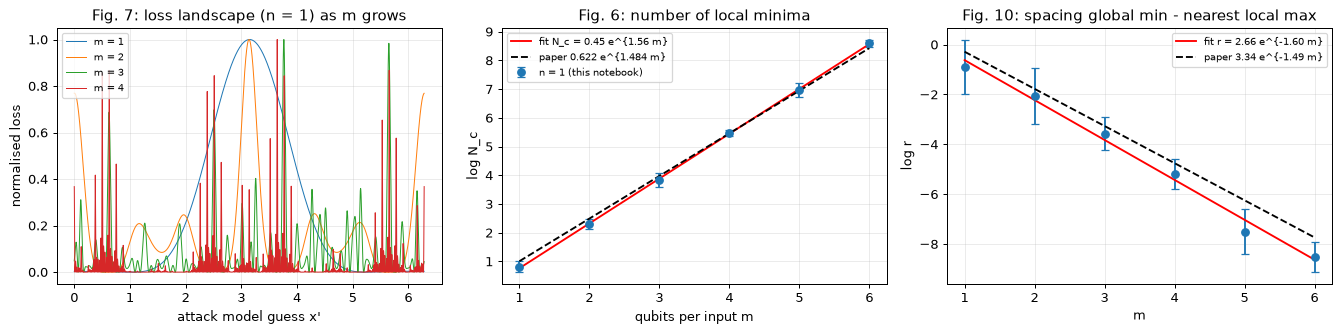

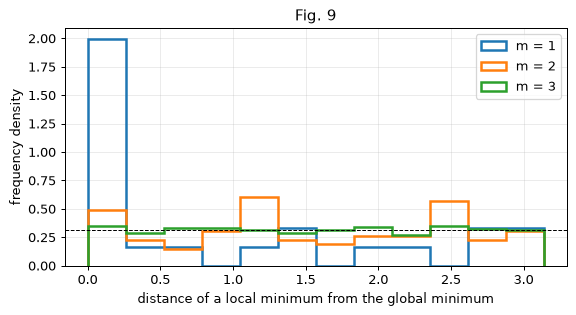

   density in first bin / uniform   ks_p      n
1                           3.391  0.000   23.0
2                           1.129  0.205  101.0
3                           1.004  0.981  472.0


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for m in [1, 2, 3, 4]:
    if m in LAND:
        g, Ln, us_ = LAND[m]["example"]
        ax[0].plot(g, Ln, lw=0.8, label=f"m = {m}")
ax[0].set_xlabel("attack model guess x'"); ax[0].set_ylabel("normalised loss"); ax[0].set_title("Fig. 7: loss landscape (n = 1) as m grows"); ax[0].legend(fontsize=8)
ax[1].errorbar(ms, logNc.mean(1), logNc.std(1), fmt="o", capsize=3, label="n = 1 (this notebook)")
ax[1].plot(ms, np.polyval(fitN, ms), "r-", label="fit N_c = %.2f e^{%.2f m}" % (np.exp(fitN[1]), fitN[0]))
ax[1].plot(ms, np.log(0.622) + 1.484 * ms, "k--", label="paper 0.622 e^{1.484 m}")
ax[1].set_xlabel("qubits per input m"); ax[1].set_ylabel("log N_c"); ax[1].set_title("Fig. 6: number of local minima"); ax[1].legend(fontsize=8)
ax[2].errorbar(ms, logr.mean(1), logr.std(1), fmt="o", capsize=3)
ax[2].plot(ms, np.polyval(fitr, ms), "r-", label="fit r = %.2f e^{%.2f m}" % (np.exp(fitr[1]), fitr[0]))
ax[2].plot(ms, np.log(3.34) - 1.49 * ms, "k--", label="paper 3.34 e^{-1.49 m}")
ax[2].set_xlabel("m"); ax[2].set_ylabel("log r"); ax[2].set_title("Fig. 10: spacing global min - nearest local max"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Fig. 9: where are the local minima relative to the global one?
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.6)); FIG9 = {}
for m in [1, 2, 3]:
    if m in LAND:
        dist = np.concatenate([r["dist"] for r in LAND[m]["recs"]])
        ax.hist(dist, bins=np.linspace(0, np.pi, 13), density=True, histtype="step", lw=2, label=f"m = {m}")
        h, _ = np.histogram(dist, bins=np.linspace(0, np.pi, 7), density=True)
        FIG9[m] = dict(first_bin_density_ratio=float(h[0] * np.pi), ks_p=float(stats.kstest(dist / np.pi, "uniform").pvalue), n=len(dist))
ax.axhline(1 / np.pi, color="k", ls="--", lw=0.8); ax.set_xlabel("distance of a local minimum from the global minimum"); ax.set_ylabel("frequency density"); ax.set_title("Fig. 9"); ax.legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame(FIG9).T.round(3).rename(columns={"first_bin_density_ratio": "density in first bin / uniform"}))

### Two inputs (`n = 2`, Fig. 8) and the exponential trend with the number of qubits

The landscape is now a 2-D torus; the circuit has `Nq = 2m` qubits.

n=2, m=1: grid 64x64, N_c = [33, 34, 36, 40] (0s)


n=2, m=2: grid 256x256, N_c = [746, 71, 372, 442] (4s)


n=2, m=3: grid 768x768, N_c = [7238, 5721, 11574, 10698] (83s)
n=2: N_c ~ 1.90 exp(2.73 m) from m = [np.int64(1), np.int64(2), np.int64(3)]


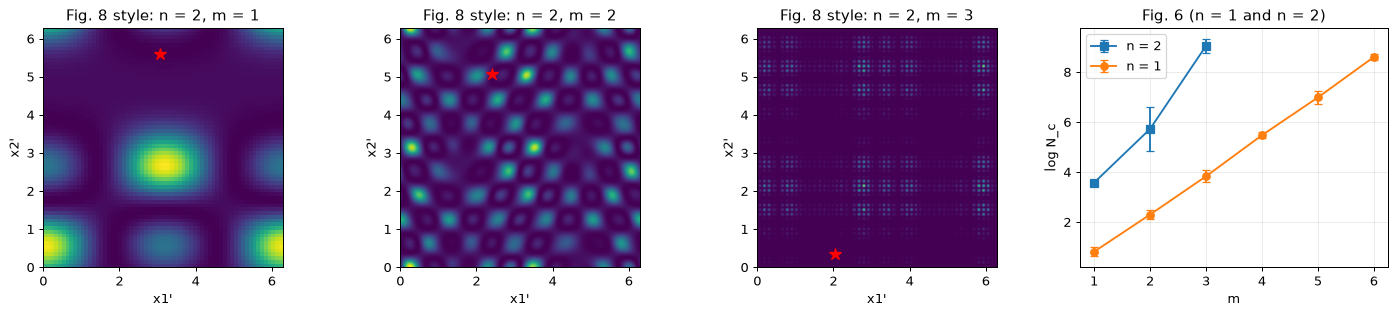

In [20]:
# n = 2 inputs (Fig. 8 and the n = 2 curve of Fig. 6): 2-D loss landscape over (x1', x2'), Nq = 2m qubits.
rb2 = rng_for("expB2")
def grid_size_2d(m):
    return {1: 64, 2: 256, 3: 768}[m]
LAND2 = {}
t0 = time.time()
for m in CFG["land2_m"]:
    mod = FourierTowerVQC(2, m, L_BLOCKS); G = grid_size_2d(m); ax1 = np.arange(G) * TWO_PI / G
    UU = np.stack(np.meshgrid(ax1, ax1, indexing="ij"), -1).reshape(-1, 2)
    recs, example = [], None
    gen = draw_landscape(mod, rb2)
    while len(recs) < CFG["land2_reps"]:
        th, ustar, y, j = next(gen)
        Lg = landscape_points(mod, th, y, ustar, UU, [j], chunk=8192)
        if Lg.max() < 1e-12:
            continue
        L2 = Lg.reshape(G, G); recs.append(int(minima_2d(L2).sum()))
        if example is None:
            example = (L2 / L2.max(), ustar)
    LAND2[m] = dict(Nc=recs, example=example)
    print(f"n=2, m={m}: grid {G}x{G}, N_c = {recs} ({time.time()-t0:.0f}s)")
m2 = np.array(CFG["land2_m"]); logN2 = np.array([np.mean(np.log(LAND2[m]["Nc"])) for m in m2])
fit2 = np.polyfit(m2, logN2, 1)
print("n=2: N_c ~ %.2f exp(%.2f m) from m = %s" % (np.exp(fit2[1]), fit2[0], list(m2)))
fig, ax = plt.subplots(1, len(m2) + 1, figsize=(4 * (len(m2) + 1), 3.6))
for k, m in enumerate(m2):
    img, us_ = LAND2[m]["example"]
    ax[k].imshow(img.T, origin="lower", extent=[0, TWO_PI, 0, TWO_PI], cmap="viridis"); ax[k].plot(*us_, "r*", ms=10)
    ax[k].set_title(f"Fig. 8 style: n = 2, m = {m}"); ax[k].set_xlabel("x1'"); ax[k].set_ylabel("x2'"); ax[k].grid(False)
ax[-1].errorbar(m2, logN2, [np.std(np.log(LAND2[m]["Nc"])) for m in m2], fmt="s-", capsize=3, label="n = 2")
ax[-1].errorbar(ms, logNc.mean(1), logNc.std(1), fmt="o-", capsize=3, label="n = 1"); ax[-1].set_xlabel("m"); ax[-1].set_ylabel("log N_c"); ax[-1].set_title("Fig. 6 (n = 1 and n = 2)"); ax[-1].legend()
plt.tight_layout(); plt.show()

## 7. Experiment C: the landscape while the federated model trains (Figs. 11-13)

A single univariate FL model (`L = 4` blocks, see the choices table) is trained on samples of a target `h` (ADAM `eta = 0.01`, batch size 10, up to 400 epochs). At several epochs we freeze `theta`, take a client with `x = 1.6371`, `y = h(x)` and compute the full
attack landscape (all `d` gradients). The paper's claim: training does not remove the high-frequency terms when `m` is large (private), but a low-frequency target fitted by a small-`m` model flattens the landscape (less private).

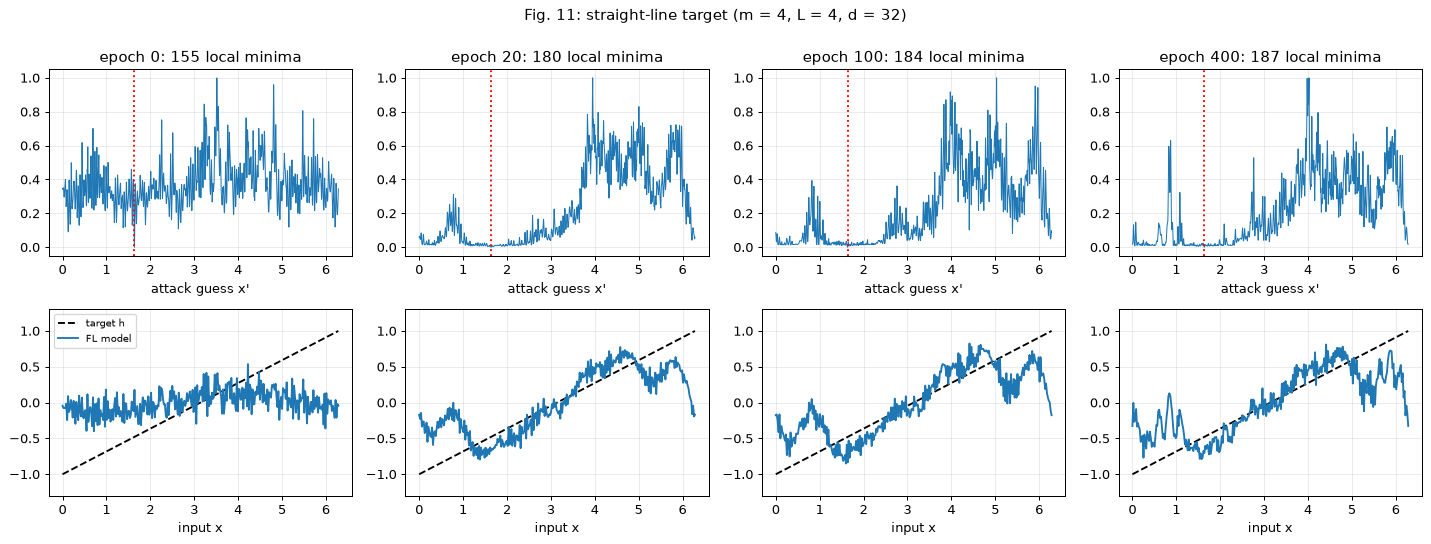

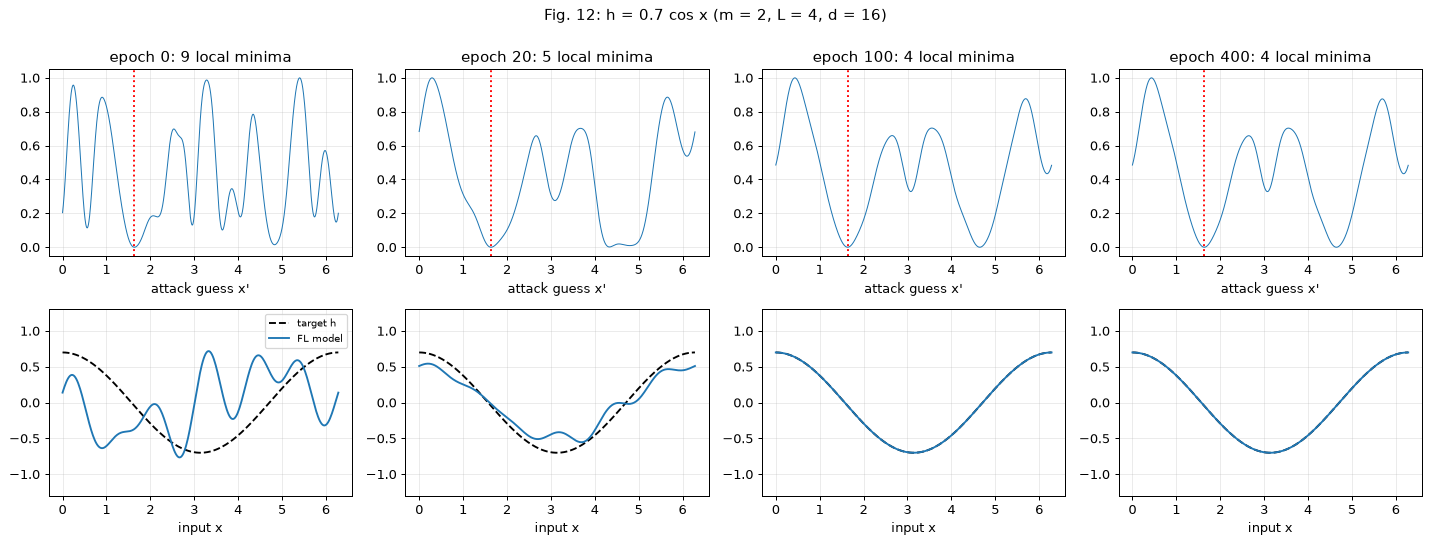

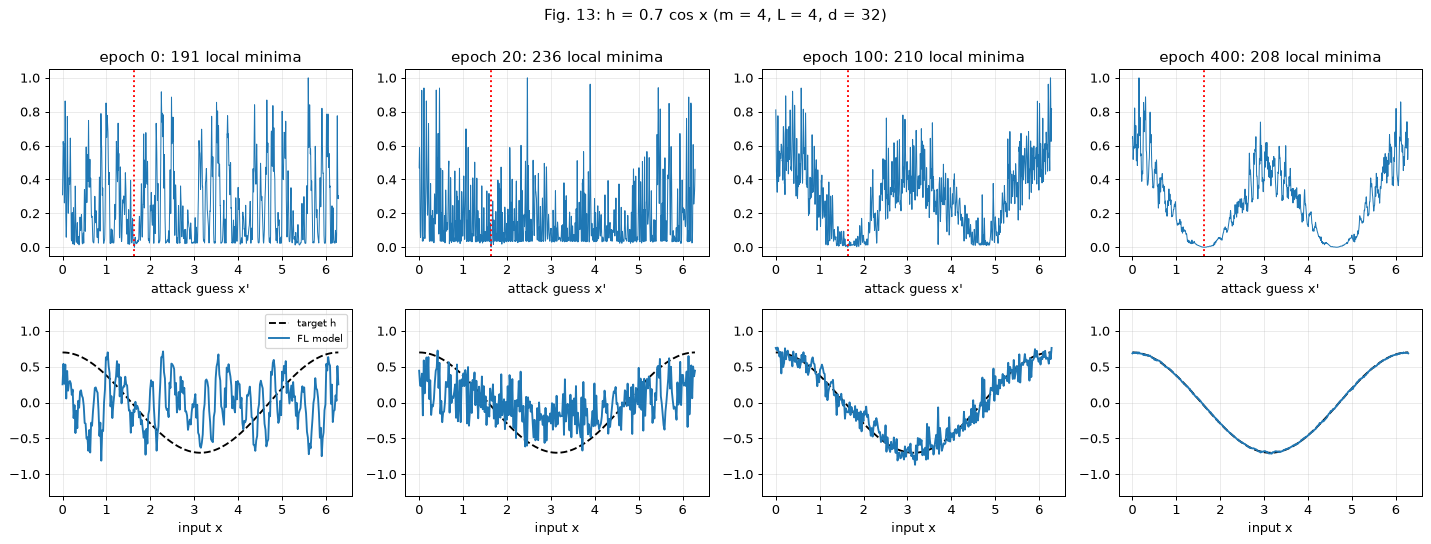

Fig. 11 (m=4, line)


,epoch,Nc,r,train_mse,fit_mse_grid
0,0,155,0.01917,0.29731,0.30089
1,20,180,0.02761,0.07479,0.12459
2,100,184,0.01381,0.05100,0.12137
3,400,187,0.01611,0.04863,0.12952


Fig. 12 (m=2, cos)


,epoch,Nc,r,train_mse,fit_mse_grid
0,0,9,0.43105,0.38470,0.41980
1,20,5,1.02777,0.01834,0.02036
2,100,4,1.01243,0.00000,0.00000
3,400,4,1.04617,0.00000,0.00000


Fig. 13 (m=4, cos)


,epoch,Nc,r,train_mse,fit_mse_grid
0,0,191,0.01611,0.33875,0.35503
1,20,236,0.01496,0.08825,0.17576
2,100,210,0.02033,0.00475,0.01353
3,400,208,0.07210,0.00001,0.00004


In [21]:
# ---- Experiment C (Figs. 11-13): the attack landscape while the federated model is being trained. ----
# Univariate FL model trained on samples of a target function h, ADAM eta = 0.01, batch size 10; at several epochs we freeze theta and compute
# the attack landscape of a client with x = 1.6371 (as in the paper, in angle units), y = h(x). The landscape uses ALL d gradients.
rc_ = rng_for("expC")
U_STAR, EPOCH_SNAPS = 1.6371, (0, 20, 100, 400)
def run_fig(m, h, name, seed_name):
    r = rng_for(seed_name)
    mod = FourierTowerVQC(1, m, L_FL); th0 = r.uniform(0, TWO_PI, (L_FL, mod.Nq, 2))
    ytr = h(u_tr)
    th_final, snaps, mse = train_vqc(mod, th0, u_tr[:, None], ytr, CFG["fl_epochs"], 10, 0.01, r, snapshots=EPOCH_SNAPS)
    N = grid_size_1d(m); grid = np.arange(N) * TWO_PI / N
    out = []
    fig, ax = plt.subplots(2, len(EPOCH_SNAPS), figsize=(4 * len(EPOCH_SNAPS), 6))
    uu = np.linspace(0, TWO_PI, 300)
    for k, ep in enumerate(EPOCH_SNAPS):
        th = snaps[ep]
        Lg = landscape_points(mod, th, float(h(U_STAR)), np.array([U_STAR]), grid[:, None], None, full=True)
        mins = minima_1d(Lg); maxs = maxima_1d(Lg); g = grid[np.argmin(Lg)]
        fu = mod.outputs(mod.psi(uu[:, None]), mod.Ms(th, params=[]))[0][0]
        fit_mse = float(np.mean((h(uu) - fu) ** 2))
        out.append(dict(epoch=ep, Nc=len(mins), r=float(circ_dist(grid[maxs], g).min()), train_mse=float(mse[ep]), fit_mse_grid=fit_mse))
        ax[0, k].plot(grid, Lg / Lg.max(), lw=0.8); ax[0, k].axvline(U_STAR, color="r", ls=":"); ax[0, k].set_title(f"epoch {ep}: {len(mins)} local minima"); ax[0, k].set_xlabel("attack guess x'")
        ax[1, k].plot(uu, h(uu), "k--", label="target h"); ax[1, k].plot(uu, fu, label="FL model"); ax[1, k].set_xlabel("input x"); ax[1, k].set_ylim(-1.3, 1.3)
        if k == 0: ax[1, k].legend(fontsize=8)
    fig.suptitle(f"{name} (m = {m}, L = {L_FL}, d = {mod.d})", y=1.0); plt.tight_layout(); plt.show()
    return pd.DataFrame(out), mse

FIG11, mse11 = run_fig(4, H_LINE, "Fig. 11: straight-line target", "fig11")
FIG12, mse12 = run_fig(2, H_COS, "Fig. 12: h = 0.7 cos x", "fig12")
FIG13, mse13 = run_fig(4, H_COS, "Fig. 13: h = 0.7 cos x", "fig13")
for nm, t in (("Fig. 11 (m=4, line)", FIG11), ("Fig. 12 (m=2, cos)", FIG12), ("Fig. 13 (m=4, cos)", FIG13)):
    print(nm); display(t.round(5))

## 8. Extension on real data: gradient inversion of Iris flowers

This is **not in the paper**. A QFL client holds real Iris flowers encoded as two PCA angles (Section 1). After a few epochs of federated-style training (parameter-shift, ADAM, batch 10) the server attacks the gradient of one held-out flower. We vary `m`,
compare with a trained classical MLP and with the closed-form dense-layer leak, and give both the paper's optimiser budget and a stronger one. Chance level for a 2-D guess within 0.5 rad is 2%.

m=1: trained, train MSE 0.312 -> 0.110, test accuracy 0.980


m=2: trained, train MSE 0.853 -> 0.133, test accuracy 0.940


m=3: trained, train MSE 1.019 -> 0.139, test accuracy 0.940


,model,budget,test_acc,P_success,chance,median_err_rad
0,"VQC n=2, m=1 (2 qubits, d=16)",paper budget,0.98,0.070,0.02,2.59
1,"VQC n=2, m=1 (2 qubits, d=16)",strong budget,0.98,0.375,0.02,2.30
2,"VQC n=2, m=2 (4 qubits, d=32)",paper budget,0.94,0.030,0.02,2.38
3,"VQC n=2, m=2 (4 qubits, d=32)",strong budget,0.94,0.090,0.02,2.14
4,"VQC n=2, m=3 (6 qubits, d=48)",paper budget,0.94,0.030,0.02,2.51
5,"VQC n=2, m=3 (6 qubits, d=48)",strong budget,0.94,0.030,0.02,2.47
6,classical MLP 2-4-1 (17 weights),paper budget,1.00,0.020,0.01,2.56
7,classical MLP 2-4-1 (17 weights),strong budget,1.00,0.170,0.01,1.64
8,classical MLP 2-4-1 (17 weights),closed form (dW/db),1.00,1.000,0.02,0.00
9,classical dense softmax layer (closed form),no optimisation,NaN,1.000,0.02,0.00


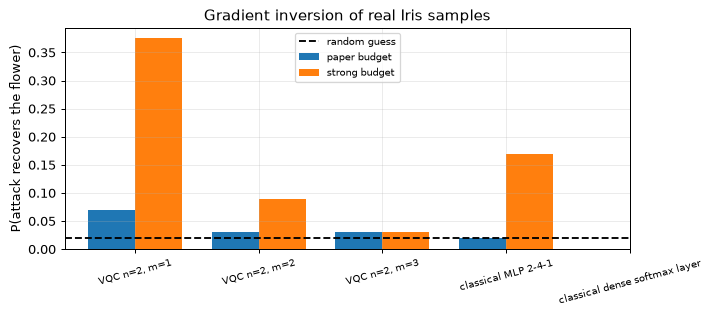

In [22]:
# ---- Extension on REAL data (not in the paper): the same server attack on the gradients of a QFL client holding real Iris flowers. ----
# n = 2 inputs (PCA angles), m qubits per input, a federated model trained for a few epochs, then the server inverts the gradient of one
# test flower (batch size 1). Success = Euclidean circular error < 0.5 rad; a random guess succeeds with probability pi*0.25/(2 pi)^2 = 0.02.
rd = rng_for("expD")
EPS_2D = 0.5; CHANCE_2D = np.pi * EPS_2D ** 2 / TWO_PI ** 2
clients = rd.choice(idx_te, CFG["iris_clients"], replace=False)
rows, ACC = [], {}
for m in CFG["iris_m"]:
    mod = FourierTowerVQC(2, m, L_FL); th0 = rd.uniform(0, TWO_PI, (L_FL, mod.Nq, 2))
    th, _, mse = train_vqc(mod, th0, U_iris[idx_tr], y_iris[idx_tr], CFG["iris_epochs"], 10, 0.05, rd)
    f_te = mod.outputs(mod.psi(U_iris[idx_te]), mod.Ms(th, params=[]))[0][0]; acc = float((np.sign(f_te) == y_iris[idx_te]).mean()); ACC[m] = acc
    Ms = mod.Ms(th)
    us = np.repeat(U_iris[clients], 10, 0); ys = np.repeat(y_iris[clients], 10); Ct, _ = mod.cost_grads(mod.psi(us), Ms, ys); U0 = rd.uniform(0, TWO_PI, (len(us), 2))
    for label, lr, it in [("paper budget", LR_PAPER, IT_PAPER), ("strong budget", CFG["ext_lr"], CFG["iris_iters"])]:
        U, loss = vqc_attack(mod, Ms, ys, Ct, U0, lr, it); e = err_circ(U, us)
        rows.append(dict(model=f"VQC n=2, m={m} ({mod.Nq} qubits, d={mod.d})", budget=label, test_acc=round(acc, 3), P_success=round((e < EPS_2D).mean(), 3),
                         chance=round(CHANCE_2D, 3), median_err_rad=round(float(np.median(e)), 2)))
    print(f"m={m}: trained, train MSE {mse[0]:.3f} -> {mse[-1]:.3f}, test accuracy {acc:.3f}")
# classical MLP 2-4-1 trained on the same data, attacked with the same budgets (non-periodic input, plain Euclidean error)
mlp = ClassicalMLP(2, 4, rd); train_mlp(mlp, U_iris[idx_tr], y_iris[idx_tr], CFG["iris_epochs"], 10, 0.05, rd)
acc_mlp = float((np.sign(mlp.f(mlp.p, U_iris[idx_te])) == y_iris[idx_te]).mean())
us = np.repeat(U_iris[clients], 10, 0); ys = np.repeat(y_iris[clients], 10); U0 = rd.uniform(0, TWO_PI, (len(us), 2))
for label, lr, it in [("paper budget", LR_PAPER, IT_PAPER), ("strong budget", CFG["ext_lr"], CFG["iris_iters"])]:
    U, loss = mlp.attack(U0, us, ys, lr, it); e = np.sqrt(((U - us) ** 2).sum(1))
    rows.append(dict(model=f"classical MLP 2-4-1 ({mlp.nparam} weights)", budget=label, test_acc=round(acc_mlp, 3), P_success=round((e < EPS_2D).mean(), 3),
                     chance=round(float((np.sqrt(((U0 - us) ** 2).sum(1)) < EPS_2D).mean()), 3), median_err_rad=round(float(np.median(e)), 2)))
uh = mlp.closed_form_leak(np.repeat(U_iris[clients], 10, 0), np.repeat(y_iris[clients], 10)); e_cf = np.sqrt(((uh - np.repeat(U_iris[clients], 10, 0)) ** 2).sum(1))
rows.append(dict(model=f"classical MLP 2-4-1 ({mlp.nparam} weights)", budget="closed form (dW/db)", test_acc=round(acc_mlp, 3), P_success=round(float((e_cf < EPS_2D).mean()), 3), chance=round(CHANCE_2D, 3), median_err_rad=float(np.median(e_cf))))
err_dense_iris = dense_softmax_inversion(U_iris[clients], (y_iris[clients] > 0).astype(int), rd)
rows.append(dict(model="classical dense softmax layer (closed form)", budget="no optimisation", test_acc=None, P_success=round(float((err_dense_iris < EPS_2D).mean()), 3), chance=round(CHANCE_2D, 3), median_err_rad=float(np.median(err_dense_iris))))
TAB_D = pd.DataFrame(rows); display(TAB_D)
fig, ax = plt.subplots(figsize=(8, 3.6)); lab = [r for r in TAB_D.model.unique()]
w = 0.38
for k, (b, c) in enumerate([("paper budget", "tab:blue"), ("strong budget", "tab:orange")]):
    vals = [TAB_D[(TAB_D.model == r) & (TAB_D.budget == b)].P_success.mean() for r in lab]
    ax.bar(np.arange(len(lab)) + (k - 0.5) * w, vals, w, color=c, label=b)
ax.axhline(CHANCE_2D, color="k", ls="--", label="random guess"); ax.set_xticks(np.arange(len(lab))); ax.set_xticklabels([l.split(" (")[0] for l in lab], rotation=15, fontsize=8)
ax.set_ylabel("P(attack recovers the flower)"); ax.set_title("Gradient inversion of real Iris samples"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Side by side with the paper

In [23]:
def row(claim, paper, ours, verdict):
    return dict(claim=claim, paper=paper, notebook=ours, verdict=verdict)

rowsV = []
p01 = (RES_A[3]["err"] < 0.1).mean()
rowsV.append(row("Fig. 4: ADAM attack on m=3 gives errors uniform on [0, pi] (no peak at 0)", "uniform / no peak",
                 f"KS p = {ks.pvalue:.3f}; P(err<0.1) = {p01:.3f} vs chance 0.032", "reproduced" if ks.pvalue > 0.01 else "not reached (distribution differs from uniform)"))
rowsV.append(row("Fig. 5 left: P(success) linear in eps (m=3)", "R^2 = 0.993", f"R^2 = {R2_LIN:.3f}, slope {slope:.3f} (random guess 0.318)",
                 "reproduced" if abs(R2_LIN - 0.993) <= 0.02 or R2_LIN > 0.993 else "not reached"))
pm = {m: (RES_A[m]["err"] < EPS_CLOSE).mean() for m in CFG["m_sweep"]}
sd = {m: np.sqrt(max(pm[m], 1e-3) * (1 - pm[m]) / len(RES_A[m]["err"])) for m in pm}
mono = all(pm[a] + 2 * sd[a] >= pm[b] - 2 * sd[b] for a, b in zip(CFG["m_sweep"][:-1], CFG["m_sweep"][1:]))
rowsV.append(row("Fig. 5 right: smaller m is less private", "lower m -> worse privacy", "P(err<0.1) by m: " + ", ".join(f"m={m}: {pm[m]:.3f}" for m in pm),
                 "reproduced" if mono and pm[1] > 3 * (0.1 / np.pi) and pm[3] < 2.5 * (0.1 / np.pi) else "not reached"))
dN = fitN[0] - 1.484
rowsV.append(row("Fig. 6/Eq. 101: N_c ~ 0.622 exp(1.484 m), n = 1", "slope 1.484, prefactor 0.622", f"slope {fitN[0]:.3f}, prefactor {np.exp(fitN[1]):.3f}",
                 "reproduced" if abs(dN) <= 0.15 else f"not reached (slope differs by {dN:+.2f})"))
rowsV.append(row("Fig. 6: n = 2 also has exponentially many minima", "exponential in m", f"slope {fit2[0]:.2f} per m (m = {list(m2)})", "reproduced" if fit2[0] > 1.0 else "not reached"))
dr = fitr[0] + 1.49
rowsV.append(row("Fig. 10/Eq. 102: valley spacing r ~ 3.34 exp(-1.49 m)", "slope -1.49, prefactor 3.34", f"slope {fitr[0]:.3f}, prefactor {np.exp(fitr[1]):.3f}",
                 ("slope reproduced; prefactor differs (definition of r not fully specified)" if abs(dr) <= 0.15 else f"not reached (slope differs by {dr:+.2f})")))
ok9 = FIG9.get(1, {}).get("first_bin_density_ratio", 0) > 1.0 and FIG9.get(2, {}).get("first_bin_density_ratio", 0) > 1.0 and FIG9.get(3, {}).get("ks_p", 0) > 0.01
rowsV.append(row("Fig. 9: minima slightly concentrated near the global one for m=1,2; uniform for m>=3", "elevated near 0 for m=1,2; uniform m=3",
                 "; ".join(f"m={m}: first-bin ratio {v['first_bin_density_ratio']:.2f}, KS p {v['ks_p']:.2f}" for m, v in FIG9.items()), "reproduced" if ok9 else "not reached (see numbers)"))
deg_ok = bool((SPEC.gradient_degree_measured == SPEC.paper_degree).all())
rowsV.append(row("Eq. 68: cost gradient has degree (5^m-1)/2 (highest frequency has a non-zero coefficient)", "d_F = (5^m-1)/2", "measured degree = " + ", ".join(f"m={r.m}: {r.gradient_degree_measured}" for r in SPEC.itertuples()), "reproduced" if deg_ok else "not reached"))
dens_ok = bool((SPEC.frequencies_populated == SPEC.paper_5_pow_m).all())
rowsV.append(row("Eq. 69: all 5^m integer frequencies in [-d_F, d_F] are populated ('dense')", "|Omega_g| = 5^m", "populated: " + ", ".join(f"m={r.m}: {r.frequencies_populated}/{r.paper_5_pow_m}" for r in SPEC.itertuples()),
                 "reproduced" if dens_ok else "not reached (the spectrum has gaps; degree and exponential growth hold)"))
rowsV.append(row("Sec. III C: dense softmax layer leaks its input exactly (batch size 1)", "closed-form recovery", f"max error {err_dense.max():.1e}", "reproduced" if err_dense.max() < 1e-8 else "not reached"))
f13, f12, f11 = FIG13.iloc[-1], FIG12.iloc[-1], FIG11.iloc[-1]
keep13 = f13.Nc >= 0.5 * FIG13.iloc[0].Nc and f13.Nc >= 20
rowsV.append(row("Fig. 13: m=4 fits 0.7 cos x yet keeps the rugged landscape (privacy kept)", "high-frequency terms preserved",
                 f"N_c {int(FIG13.iloc[0].Nc)} -> {int(f13.Nc)}; fit MSE {f13.fit_mse_grid:.3f}", "reproduced" if keep13 and f13.fit_mse_grid < 0.05 else "not reached"))
# criterion fixed before the final runs: simplified = at least half of the minima gone OR the global valley at least twice as wide
lose12 = (f12.Nc <= 0.5 * FIG12.iloc[0].Nc) or (f12.r >= 2 * FIG12.iloc[0].r)
rowsV.append(row("Fig. 12: m=2 fitting 0.7 cos x suppresses high frequencies (reduced privacy)", "simplified landscape",
                 f"N_c {int(FIG12.iloc[0].Nc)} -> {int(f12.Nc)}, valley r {FIG12.iloc[0].r:.3f} -> {f12.r:.3f}; fit MSE {f12.fit_mse_grid:.3f}", "reproduced" if lose12 and f12.fit_mse_grid < 0.05 else "not reached"))
keep11 = f11.Nc >= 0.5 * FIG11.iloc[0].Nc and f11.Nc >= 20
rowsV.append(row("Fig. 11: m=4 straight-line target keeps high-frequency terms", "landscape stays rugged",
                 f"N_c {int(FIG11.iloc[0].Nc)} -> {int(f11.Nc)}; fit MSE {f11.fit_mse_grid:.3f}", "reproduced" if keep11 else "not reached"))
rowsV.append(row("Sec. VI: Buchberger / Nyquist hardness bounds, ML-attack <-> over/under-parameterisation duality", "analytic arguments", "proofs, not experiments", "cannot be checked"))
VERD = pd.DataFrame(rowsV)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
display(VERD)
print(VERD.verdict.str.split(" ").str[0].value_counts().to_string())
print("total run time: %.1f min" % ((time.time() - T0) / 60))

,claim,paper,notebook,verdict
0,"Fig. 4: ADAM attack on m=3 gives errors uniform on [0, pi] (no peak at 0)",uniform / no peak,KS p = 0.145; P(err<0.1) = 0.040 vs chance 0.032,reproduced
1,Fig. 5 left: P(success) linear in eps (m=3),R^2 = 0.993,"R^2 = 0.999, slope 0.315 (random guess 0.318)",reproduced
2,Fig. 5 right: smaller m is less private,lower m -> worse privacy,"P(err<0.1) by m: m=1: 0.213, m=2: 0.182, m=3: 0.040, m=4: 0.023, m=5: 0.034, m=6: 0.029",reproduced
3,"Fig. 6/Eq. 101: N_c ~ 0.622 exp(1.484 m), n = 1","slope 1.484, prefactor 0.622","slope 1.561, prefactor 0.451",reproduced
4,Fig. 6: n = 2 also has exponentially many minima,exponential in m,"slope 2.73 per m (m = [np.int64(1), np.int64(2), np.int64(3)])",reproduced
5,Fig. 10/Eq. 102: valley spacing r ~ 3.34 exp(-1.49 m),"slope -1.49, prefactor 3.34","slope -1.601, prefactor 2.663",slope reproduced; prefactor differs (definition of r not fully specified)
6,"Fig. 9: minima slightly concentrated near the global one for m=1,2; uniform for m>=3","elevated near 0 for m=1,2; uniform m=3","m=1: first-bin ratio 3.39, KS p 0.00; m=2: first-bin ratio 1.13, KS p 0.20; m=3: first-bin ratio 1.00, KS p 0.98",reproduced
7,Eq. 68: cost gradient has degree (5^m-1)/2 (highest frequency has a non-zero coefficient),d_F = (5^m-1)/2,"measured degree = m=1: 2, m=2: 12, m=3: 62, m=4: 312",reproduced
8,"Eq. 69: all 5^m integer frequencies in [-d_F, d_F] are populated ('dense')",|Omega_g| = 5^m,"populated: m=1: 5/5, m=2: 21/25, m=3: 91/125, m=4: 339/625",not reached (the spectrum has gaps; degree and exponential growth hold)
9,Sec. III C: dense softmax layer leaks its input exactly (batch size 1),closed-form recovery,max error 8.9e-16,reproduced


verdict
reproduced    11
slope          1
not            1
cannot         1
total run time: 20.7 min


## 10. Reading the paper critically

* **What the numbers support.** For the paper's own protocol (m = 3, ADAM 0.01, 60 iterations) the attack is no better than guessing, and the exponential growth of the number of
  local minima in `m` is reproduced (slope about 1.5 per qubit, valley width shrinking like `e^(-1.6 m)`). That is the numerical core of the paper and it holds up.
* **The budget caveat.** With `eta = 0.01` and 60 iterations ADAM cannot travel more than about 0.6 rad, so *any* model whose minimum is farther than that from the initial guess "resists" the attack.
  Fig. 4 on its own therefore tests the optimiser budget as much as the landscape. The tables in Experiment A separate the two: with a 5-10x stronger optimiser, the classical MLP is inverted (success far above chance) while the `m = 3` VQC stays at chance, which is the real evidence for the claim.
  Small `m` is a different story: for `m = 1` and `m = 2` a stronger optimiser recovers a large fraction of inputs (those starting in the global basin), so a few qubits per input give little protection.
* **Privacy here is a *search cost*, not secrecy.** For `n = 1` the whole circle can be scanned: the brute-force table in Experiment A shows that a grid of `~16 x 5^m` evaluations of the full-gradient loss locates the exact input (the loss vanishes only there).
  That is cheap for small `m`, exponential in `m n` as the paper says, but it is an *efficiency* statement; nothing is information-theoretically hidden, and the client pays with `m n` qubits. A real server could also exploit the circuit structure (grid starts, many restarts, algebraic methods).
* **The spectrum has gaps.** The paper calls the gradient spectrum dense (all `5^m` integer frequencies). Section 3 finds the *degree* exactly as predicted, but a growing fraction of the integer frequencies has coefficient exactly zero, so the polynomial is sparser than claimed (the exponential degree, which drives the oscillation, is what matters for the landscape).
* **Periodicity, not quantumness.** The Fourier-feature classical MLP in Experiment A shows what the data suggest: it is the highly periodic feature map that creates the rugged landscape, which is exactly the open question the authors raise in their conclusion. We did not train that classical model to compete on accuracy.
* **Idealised setting.** Exact gradients (no shot noise), known label, known `theta`, batch size 1, and synthetic uniform inputs. The Iris extension shows the same ordering for the VQC on real data (with a stronger optimiser `m = 1` is inverted in about 40% of the cases, while `m = 2` and `m = 3` stay below 10%, against 2% for a random guess), with only two inputs; the hardness scales as `5^(m n)` so more inputs help the defender.
* **Optimisation attacks versus analytic attacks.** The closed-form rows in the tables show that a classical network with biases leaks its input exactly from one gradient (first-layer weight gradient divided by bias gradient), *including* the MLP with periodic features (the input is read back as `atan2`). The Fourier features only make the *optimisation-based* attack hard; the VQC has no such algebraic shortcut, which is its real advantage in this comparison. Note also that the trained classical MLP on Iris resisted the optimiser at these budgets (saturated `tanh` units flatten its landscape), so a failed optimisation attack on a classical net is not evidence of privacy.
* **Training matters.** Fig. 12 is an honest warning: a model that only needs low frequencies loses its protection. Privacy depends on the learned `theta`, not only on the architecture.
* **Not checked.** The complexity-theoretic arguments (Buchberger bound, Nyquist argument, over/under-parameterisation duality) are analytic and are not tested here; the "dead parameters" of the parity-measured HEA (zero gradient) also show that not every shared number is informative.

## 11. Exercises

1. Change `L_BLOCKS` to 1 and to 4 and repeat Experiment B for `m = 1..4`. Does the number of local minima depend on the depth, or only on `m`?
2. Replace the encoding multiplier `5^k` by `2^k` or by 1 (every qubit gets `RX(u)`). Count the local minima again and relate the result to the size of the frequency spectrum in Section 3.
3. Implement the brute-force attacker: evaluate the loss on a grid with `16 x 5^m` points and take the argmin. Measure its success and its cost for `m = 1..6` and compare it with ADAM from random starts.
4. Give the attacker a smaller label uncertainty: do not reveal `y` and attack with both `y = +1` and `y = -1`. Is the true input still the unique zero of the loss?
5. Add shot noise to the shared gradients (e.g. Gaussian noise of standard deviation `1/sqrt(shots)` on every `C_p`). Does the noise help or hurt the attacker for `m = 1` and `m = 3`?